# D1a descriptive deep dives — 2026-09-10

**Purpose.** Unpack the D1a all-representation heatmap before making biological claims. The notebook moves from panel taxonomy → supported-patient transfer → three panel case studies → label-free Stage 1 diagnostics → a one-score pathway baseline → cell-level ranking-error audits with RNA/CITE metadata.

**Focus panels.** `HALLMARK_ALLOGRAFT_REJECTION`, `HALLMARK_APOPTOSIS`, and `HALLMARK_TNFA_SIGNALING_VIA_NFKB`.

**Scope.** This is a read-only diagnostic over completed old34 artifacts. It does not rerun Stage 0 or the 643-representation Stage 1/2 grid. It writes derived tables and figures under the namespaced `d1a_deep_dive_20260910` analysis folders.

**Claim boundary.** Results are descriptive. The globally selected regularizer and the displayed “best” representation were selected using the same LOPO folds. Stage 1 is transductive. Cell-level error groups below use a post-hoc prevalence-matched rank cutoff because AUPRC has no operating threshold; they are not deployment classifications.

## 1. What “fits at different K are not nested” means

A sequence is **nested** when every smaller feature space is literally contained in the next one. For example, if PCA is fit once at K=40 and downstream probes use columns 1–5, 1–10, 1–20, and 1–40 from that same score matrix, the K=5 subspace is contained in K=10, which is contained in K=20, and so on.

That is not how this grid was constructed: each method is refit independently at K=5, 10, 20, and 40. For PCA, the ideal leading subspaces target a nested eigenspace, although independent randomized fits need not return numerically identical columns. For FA and rotated FactoSig, all loadings are jointly re-optimized when K changes; factors can rotate, split, merge, or reorder. Therefore `FA K=10` is not “FA K=5 plus five new factors.” I was contrasting the current independent-fit grid with a possible nested-prefix sensitivity experiment—not implying that the existing pipeline claimed nesting.

Increasing K:

- keeps the same Stage 0 genes but represents them with more latent coordinates;
- weakens the information bottleneck and can retain lower-variance or more localized structure;
- refits the latent geometry, especially for FA/FactoSig;
- gives Stage 2 more candidate features and can change the selected penalty/C and sparsity pattern.

Consequently, a K trend can reflect added rank, changed geometry, changed Stage 2 regularization, or confounded cell-state/lineage structure. It is not automatically evidence that “factor 21–40 contain the phenotype.”

## 2. Panel taxonomy used in D1

The 47 D1 rows contain four display classes:

1. **Individual gene sets (34):** exactly one Hallmark, Reactome, or KEGG set, such as TNFα/NF-κB.
2. **Biology-group unions (7):** manually defined unions of several related old34 sets, such as `proliferation metabolism` or `cytokine JAK-STAT`.
3. **Knowledge-union controls (2):** `full_34` and `core_only`; broad unions rather than individual hypotheses.
4. **Data-driven controls (4):** HVG 500/1,000/3,000/10,000.

`all_filtered_mrd_gene_universe` exists in the Stage 0 manifest but has no full D1 Stage 2 grid and is not a plotted D1 row. The next figure groups the y-axis by these classes rather than mixing them in a performance-only order.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.sparse import load_npz
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 120)

EXPERIMENT_ID = "20260525_060508_stage0_mrd_old34_broad_screen_82db5093"


def find_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "experiments").exists():
            return candidate
    fallback = Path("/home/minhang/mds_project/sc_classification")
    if fallback.exists():
        return fallback
    raise FileNotFoundError("Could not locate sc_classification repository root")


REPO_ROOT = find_repo_root()
EXP_DIR = REPO_ROOT / "experiments" / EXPERIMENT_ID
BASE_DIAGNOSTIC_DIR = EXP_DIR / "analysis" / "scorecards" / "stage2_diagnostic"
TABLE_DIR = BASE_DIAGNOSTIC_DIR / "d1a_deep_dive_20260910"
FIGURE_DIR = EXP_DIR / "analysis" / "figures" / "stage2_diagnostic" / "d1a_deep_dive_20260910"
CACHE_DIR = EXP_DIR / "analysis" / "cache" / "stage2_diagnostic" / "d1a_deep_dive_20260910"
for directory in (TABLE_DIR, FIGURE_DIR, CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SOURCE_PATHS = {
    "atlas_representation": BASE_DIAGNOSTIC_DIR / "old34_d1_atlas_representation_table.csv",
    "atlas_patient": BASE_DIAGNOSTIC_DIR / "old34_d1_atlas_supported_patient_metrics.csv",
    "d1e_selection": BASE_DIAGNOSTIC_DIR / "old34_d1e_best_dr_vs_direct_gene_selection.csv",
    "stage0_manifest": EXP_DIR / "preprocessing" / "panels" / "stage0_panel_manifest.csv",
    "stage0_scorecard": EXP_DIR / "analysis" / "scorecards" / "stage0_mrd_old34_broad_scorecard.csv",
    "direct_stage0_scorecard": EXP_DIR / "analysis" / "scorecards" / "old34_direct_gene_all_v1" / "stage0_mrd_old34_broad_scorecard.csv",
    "selected_lopo_coefficients": EXP_DIR / "analysis" / "cache" / "stage2_diagnostic" / "layer4_5" / "selected_lopo_coefficients.pkl.gz",
    "cohort_cache": EXP_DIR / "analysis" / "cache" / "stage2_diagnostic" / "deg_hvg_lowsupport_v1" / "mrd_cite_binary_log1p_15560.h5ad",
}
missing = [str(path) for path in SOURCE_PATHS.values() if not path.exists()]
assert not missing, f"Missing required completed artifacts: {missing}"

GENERATED_FIGURES: list[Path] = []
GENERATED_TABLES: list[Path] = []


def save_figure(fig: plt.Figure, stem: str, *, dpi: int = 180) -> Path:
    png = FIGURE_DIR / f"{stem}.png"
    fig.savefig(png, dpi=dpi, bbox_inches="tight")
    fig.savefig(png.with_suffix(".pdf"), bbox_inches="tight")
    GENERATED_FIGURES.extend([png, png.with_suffix(".pdf")])
    print(png)
    return png


def write_csv(frame: pd.DataFrame, filename: str, *, index: bool = False, compression=None) -> Path:
    path = TABLE_DIR / filename
    frame.to_csv(path, index=index, compression=compression)
    GENERATED_TABLES.append(path)
    print(path)
    return path


METHOD_ORDER = ["pca", "fa", "factosig", "factosig_promax"]
K_ORDER = [5, 10, 20, 40]
CONFIG_ORDER = ["direct_gene"] + [f"{method}|K={k}" for method in METHOD_ORDER for k in K_ORDER]
SUPPORTED_PATIENTS = ["P01", "P02", "P03", "P04", "P06", "P07", "P09"]
FOCUS = {
    "single_geneset__hallmark_allograft_rejection": {
        "label": "Allograft rejection",
        "selected_configuration": "factosig_promax|K=40",
    },
    "single_geneset__hallmark_apoptosis": {
        "label": "Apoptosis",
        "selected_configuration": "factosig_promax|K=40",
    },
    "single_geneset__hallmark_tnfa_signaling_via_nfkb": {
        "label": "TNFα signaling via NF-κB",
        "selected_configuration": "factosig_promax|K=20",
    },
}

print("Repository:", REPO_ROOT)
print("Experiment:", EXP_DIR)
print("Tables:", TABLE_DIR)
print("Figures:", FIGURE_DIR)

Repository: /home/minhang/mds_project/sc_classification
Experiment: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093
Tables: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910
Figures: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910


In [2]:
atlas_representation = pd.read_csv(SOURCE_PATHS["atlas_representation"], low_memory=False)
atlas_patient = pd.read_csv(SOURCE_PATHS["atlas_patient"], low_memory=False)
d1e_selection = pd.read_csv(SOURCE_PATHS["d1e_selection"], low_memory=False)
stage0_manifest = pd.read_csv(SOURCE_PATHS["stage0_manifest"], low_memory=False)

PANEL_CLASS_MAP = {
    "single_geneset_only": "Individual gene set",
    "single_group_only": "Biology-group union",
    "full_control": "Knowledge-union control",
    "core_only": "Knowledge-union control",
    "hvg_anchor_control": "Data-driven HVG control",
}
PANEL_CLASS_ORDER = [
    "Data-driven HVG control",
    "Knowledge-union control",
    "Biology-group union",
    "Individual gene set",
]

panel_meta = atlas_representation[
    ["stage0_panel_id", "stage0_panel_type", "short_panel_label", "panel_label_with_genes", "n_covered_genes", "atlas_row_block"]
].drop_duplicates("stage0_panel_id").copy()
panel_meta["panel_class"] = panel_meta["stage0_panel_type"].map(PANEL_CLASS_MAP)
assert panel_meta["panel_class"].notna().all()
assert panel_meta["panel_class"].value_counts().to_dict() == {
    "Individual gene set": 34,
    "Biology-group union": 7,
    "Data-driven HVG control": 4,
    "Knowledge-union control": 2,
}

best_p20 = atlas_representation.groupby("stage0_panel_id")["patient_p20_lift"].max()
panel_meta["best_p20_lift"] = panel_meta["stage0_panel_id"].map(best_p20)
panel_meta["panel_class"] = pd.Categorical(panel_meta["panel_class"], PANEL_CLASS_ORDER, ordered=True)
panel_meta = panel_meta.sort_values(["panel_class", "best_p20_lift", "panel_label_with_genes"], ascending=[True, False, True])
panel_order = panel_meta["panel_label_with_genes"].tolist()

biological_winners = d1e_selection.loc[d1e_selection["atlas_row_block"].eq("biological")].copy()
winner_k_counts = biological_winners["best_dr_k"].astype(int).value_counts().sort_index().rename_axis("K").rename("n_panel_winners").reset_index()
winner_method_counts = biological_winners["best_dr_method"].value_counts().rename_axis("method").rename("n_panel_winners").reset_index()

individual_ids = set(panel_meta.loc[panel_meta["panel_class"].eq("Individual gene set"), "stage0_panel_id"])
best_individual_median = biological_winners.loc[biological_winners["stage0_panel_id"].isin(individual_ids)].sort_values(
    ["best_dr_median_lift", "best_dr_p20_lift"], ascending=False
).iloc[0]
best_individual_floor = atlas_representation.loc[
    atlas_representation["stage0_panel_id"].isin(individual_ids)
    & atlas_representation["stage1_method"].ne("direct_gene")
].sort_values(["patient_p20_lift", "patient_median_lift"], ascending=False).iloc[0]

write_csv(panel_meta.astype({"panel_class": "string"}), "d1dd_panel_taxonomy.csv")
write_csv(winner_k_counts, "d1dd_best_median_winner_counts_by_k.csv")
write_csv(winner_method_counts, "d1dd_best_median_winner_counts_by_method.csv")

display(panel_meta.groupby("panel_class", observed=True).agg(n_panels=("stage0_panel_id", "size"), min_genes=("n_covered_genes", "min"), max_genes=("n_covered_genes", "max")))
display(winner_k_counts.T)
display(winner_method_counts.T)
print(
    "Best individual set by median DR lift:",
    best_individual_median["panel_label_with_genes"],
    best_individual_median["best_dr_configuration"],
    f"{100 * best_individual_median['best_dr_median_lift']:.2f} pp",
)
print(
    "Best individual set by p20 DR lift:",
    best_individual_floor["panel_label_with_genes"],
    best_individual_floor["configuration"],
    f"{100 * best_individual_floor['patient_p20_lift']:.2f} pp",
)

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_panel_taxonomy.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_best_median_winner_counts_by_k.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_best_median_winner_counts_by_method.csv


,n_panels,min_genes,max_genes
panel_class,,,
Data-driven HVG control,4,500,10000
Knowledge-union control,2,1648,2719
Biology-group union,7,146,948
Individual gene set,34,12,616


,0,1,2
K,10,20,40
n_panel_winners,4,13,24


,0,1,2,3
method,factosig_promax,fa,pca,factosig
n_panel_winners,12,11,9,9


Best individual set by median DR lift: tnfa signaling via nfkb (172) factosig_promax|K=20 18.06 pp
Best individual set by p20 DR lift: inflammatory response (135) fa|K=40 4.72 pp


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD1_grouped_panel_taxonomy_transfer_atlas.png


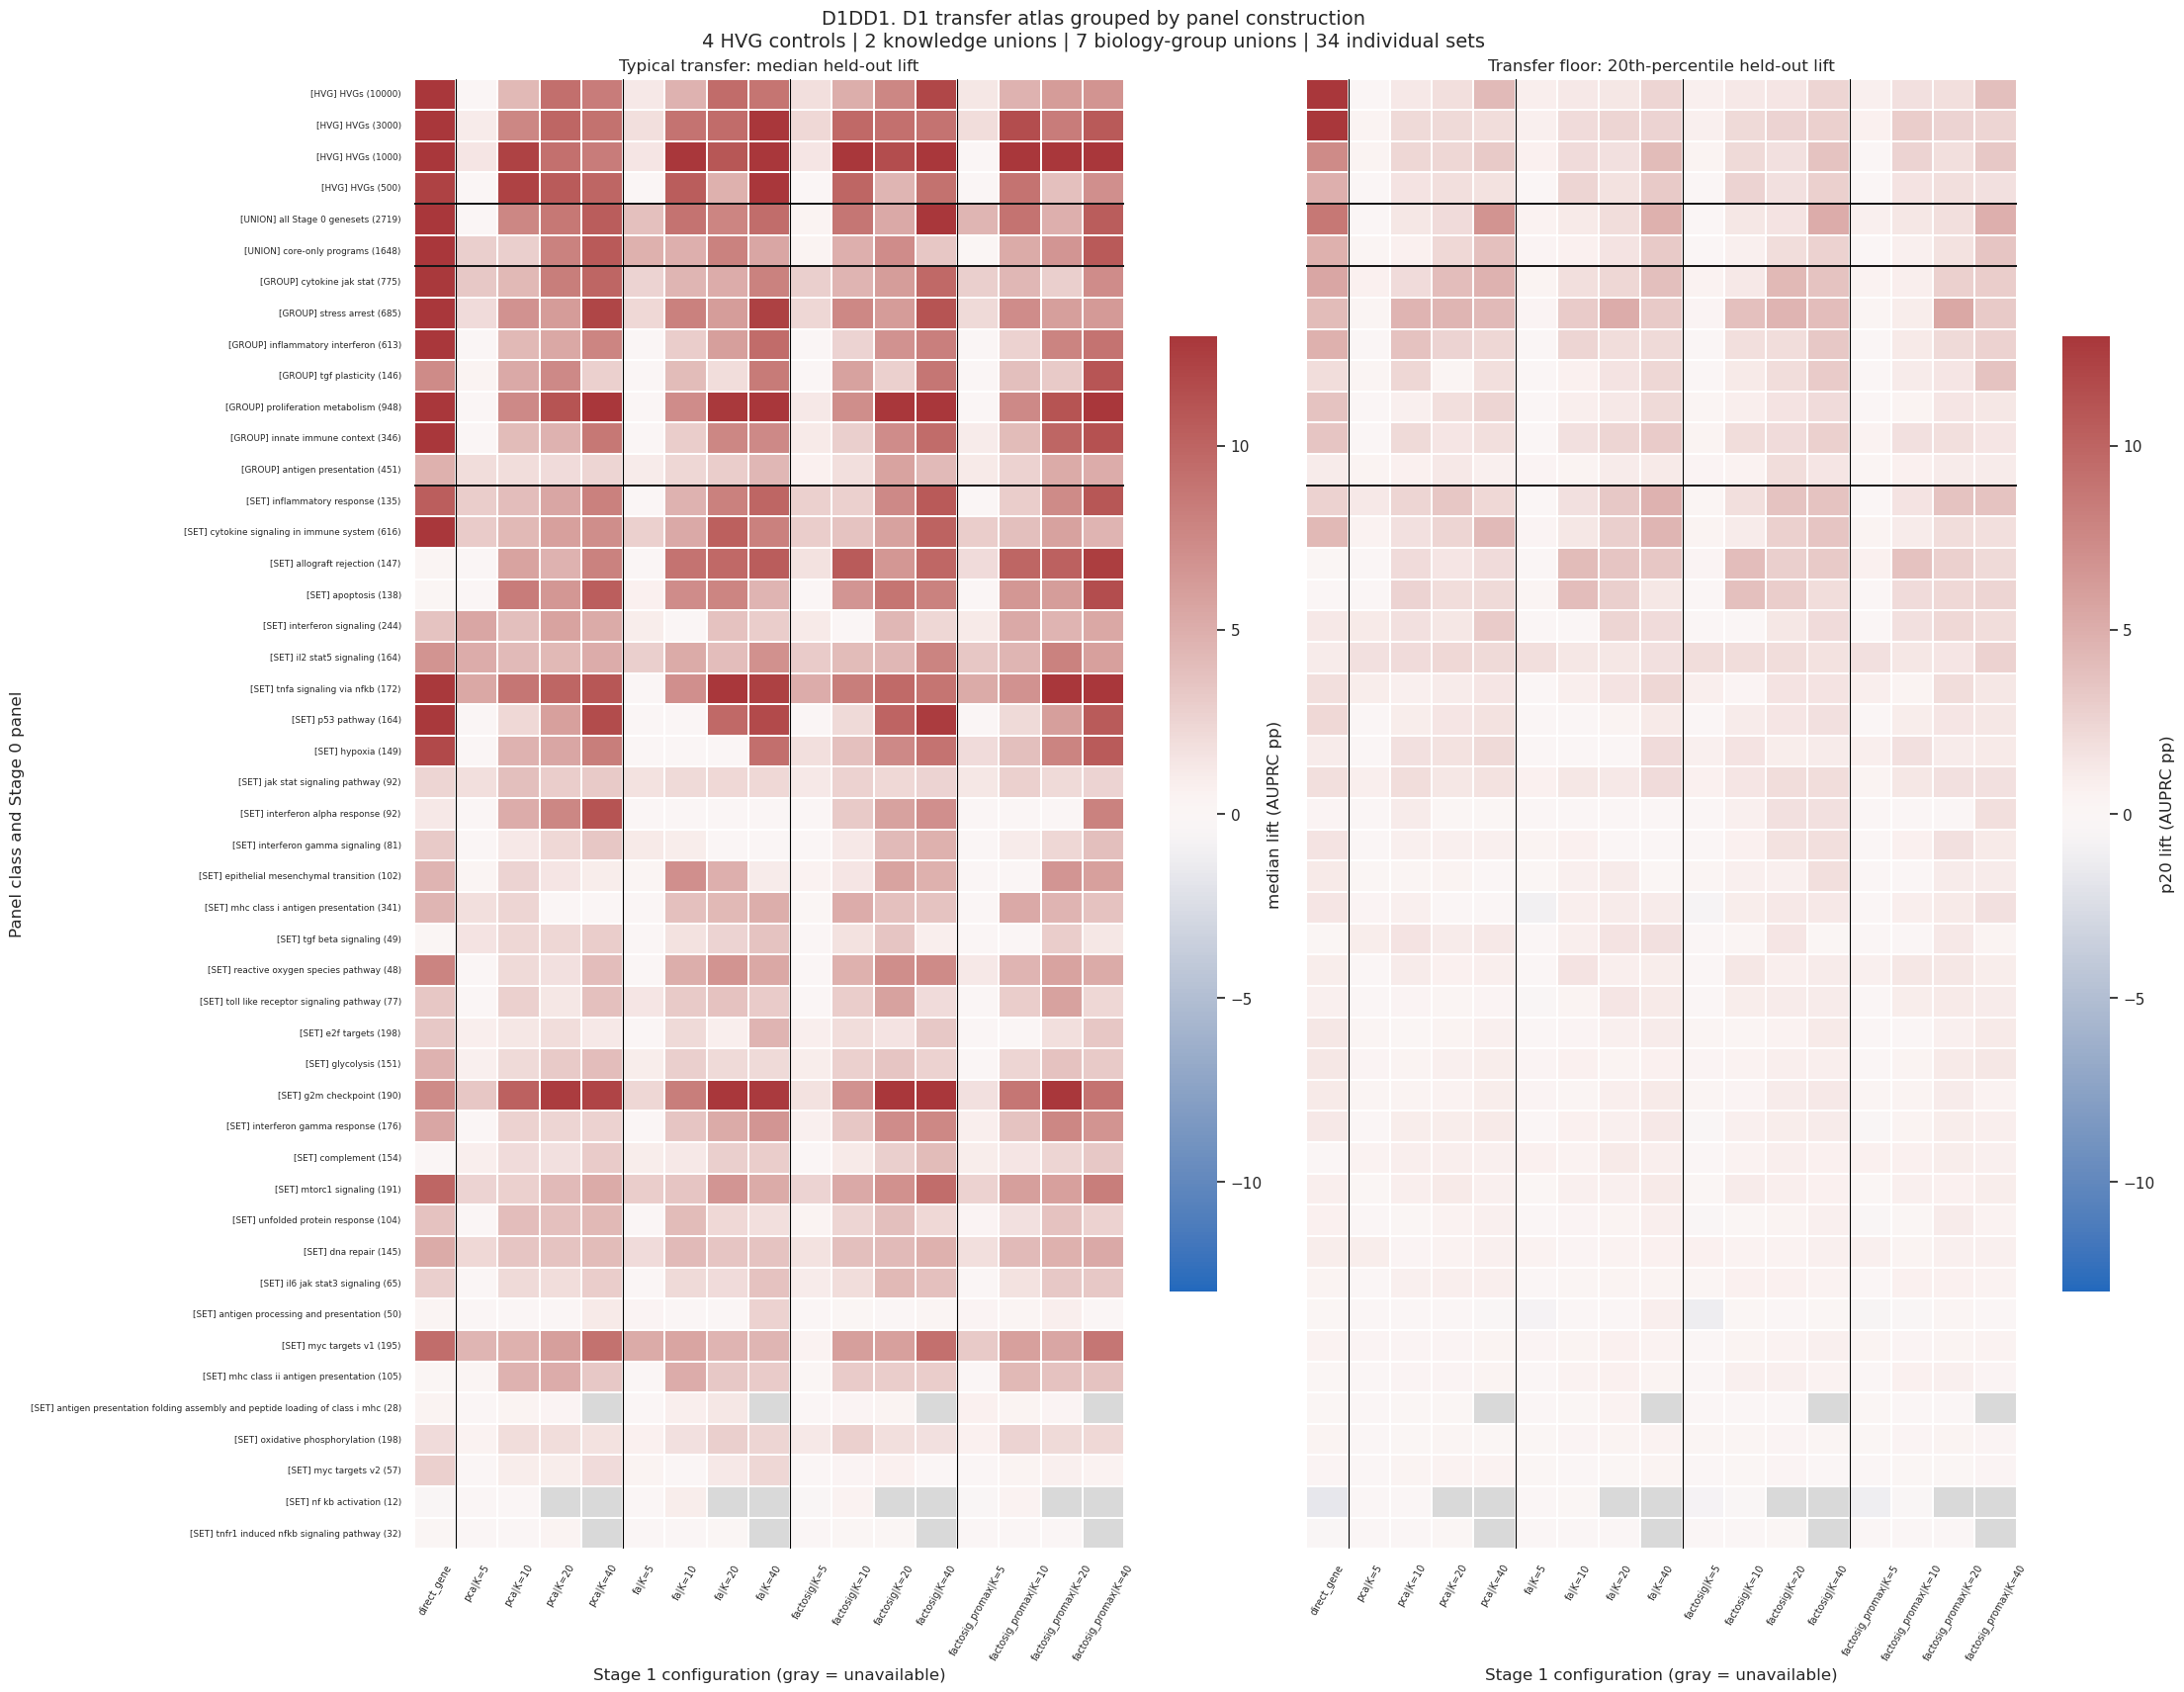

In [ ]:
# D1DD1 — same 777 D1 cells, but grouped by panel construction rather than performance alone.
class_prefix = {
    "Data-driven HVG control": "HVG",
    "Knowledge-union control": "UNION",
    "Biology-group union": "GROUP",
    "Individual gene set": "SET",
}
label_to_class = panel_meta.set_index("panel_label_with_genes")["panel_class"].astype(str).to_dict()
display_labels = [f"[{class_prefix[label_to_class[label]]}] {label}" for label in panel_order]

median_matrix = (
    atlas_representation.pivot(index="panel_label_with_genes", columns="configuration", values="patient_median_lift")
    .reindex(index=panel_order, columns=CONFIG_ORDER)
    * 100
)
p20_matrix = (
    atlas_representation.pivot(index="panel_label_with_genes", columns="configuration", values="patient_p20_lift")
    .reindex(index=panel_order, columns=CONFIG_ORDER)
    * 100
)
values = np.concatenate([median_matrix.to_numpy().ravel(), p20_matrix.to_numpy().ravel()])
values = values[np.isfinite(values)]
vmax = max(float(np.quantile(np.abs(values), 0.98)), 3.0)
cmap = plt.get_cmap("vlag").copy()
cmap.set_bad("#d9d9d9")

class_counts = panel_meta["panel_class"].value_counts(sort=False).reindex(PANEL_CLASS_ORDER).astype(int)
row_boundaries = np.cumsum(class_counts.to_numpy())[:-1]
fig, axes = plt.subplots(1, 2, figsize=(22, 17), sharey=True, constrained_layout=True)
for ax, matrix, title, cbar_label in [
    (axes[0], median_matrix, "Typical transfer: median held-out lift", "median lift (AUPRC pp)"),
    (axes[1], p20_matrix, "Transfer floor: 20th-percentile held-out lift", "p20 lift (AUPRC pp)"),
]:
    sns.heatmap(
        matrix,
        cmap=cmap,
        center=0,
        vmin=-vmax,
        vmax=vmax,
        linewidths=0.18,
        linecolor="white",
        cbar_kws={"label": cbar_label, "shrink": 0.65},
        yticklabels=display_labels,
        ax=ax,
    )
    for boundary in [1, 5, 9, 13]:
        ax.axvline(boundary, color="black", lw=0.8)
    for boundary in row_boundaries:
        ax.axhline(boundary, color="black", lw=1.3)
    ax.set_title(title)
    ax.set_xlabel("Stage 1 configuration (gray = unavailable)")
    ax.set_ylabel("Panel class and Stage 0 panel" if ax is axes[0] else "")
    ax.tick_params(axis="x", labelsize=7, rotation=60)
    ax.tick_params(axis="y", labelsize=6.4)
fig.suptitle(
    "D1DD1. D1 transfer atlas grouped by panel construction\n"
    "4 HVG controls | 2 knowledge unions | 7 biology-group unions | 34 individual sets",
    fontsize=14,
)xw
save_figure(fig, "D1DD1_grouped_panel_taxonomy_transfer_atlas")
plt.show()

## 3. Start with patients, then focus panels

D1a compresses seven held-out patient lifts into their median; D1b compresses them into a lower-tail p20. The next analyses reverse that compression.

- D1DD2 first shows the across-panel K pattern separately for each supported patient.
- D1DD3 shows every method × K value, plus direct genes, for each focus panel and patient.
- D1DD4 shows median and p20 trajectories separately. This matters because the median-optimal K need not maximize the transfer floor.
- D1DD5 directly pairs each patient’s selected-DR and direct-gene lift.

Every value still uses the one globally selected Stage 2 regularizer for that representation. These are held-out Stage 2 predictions, but the regularizer/representation review is not nested.

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_patient_k_summary_across_biological_panels.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD2_patient_specific_k_trends_across_panels.png


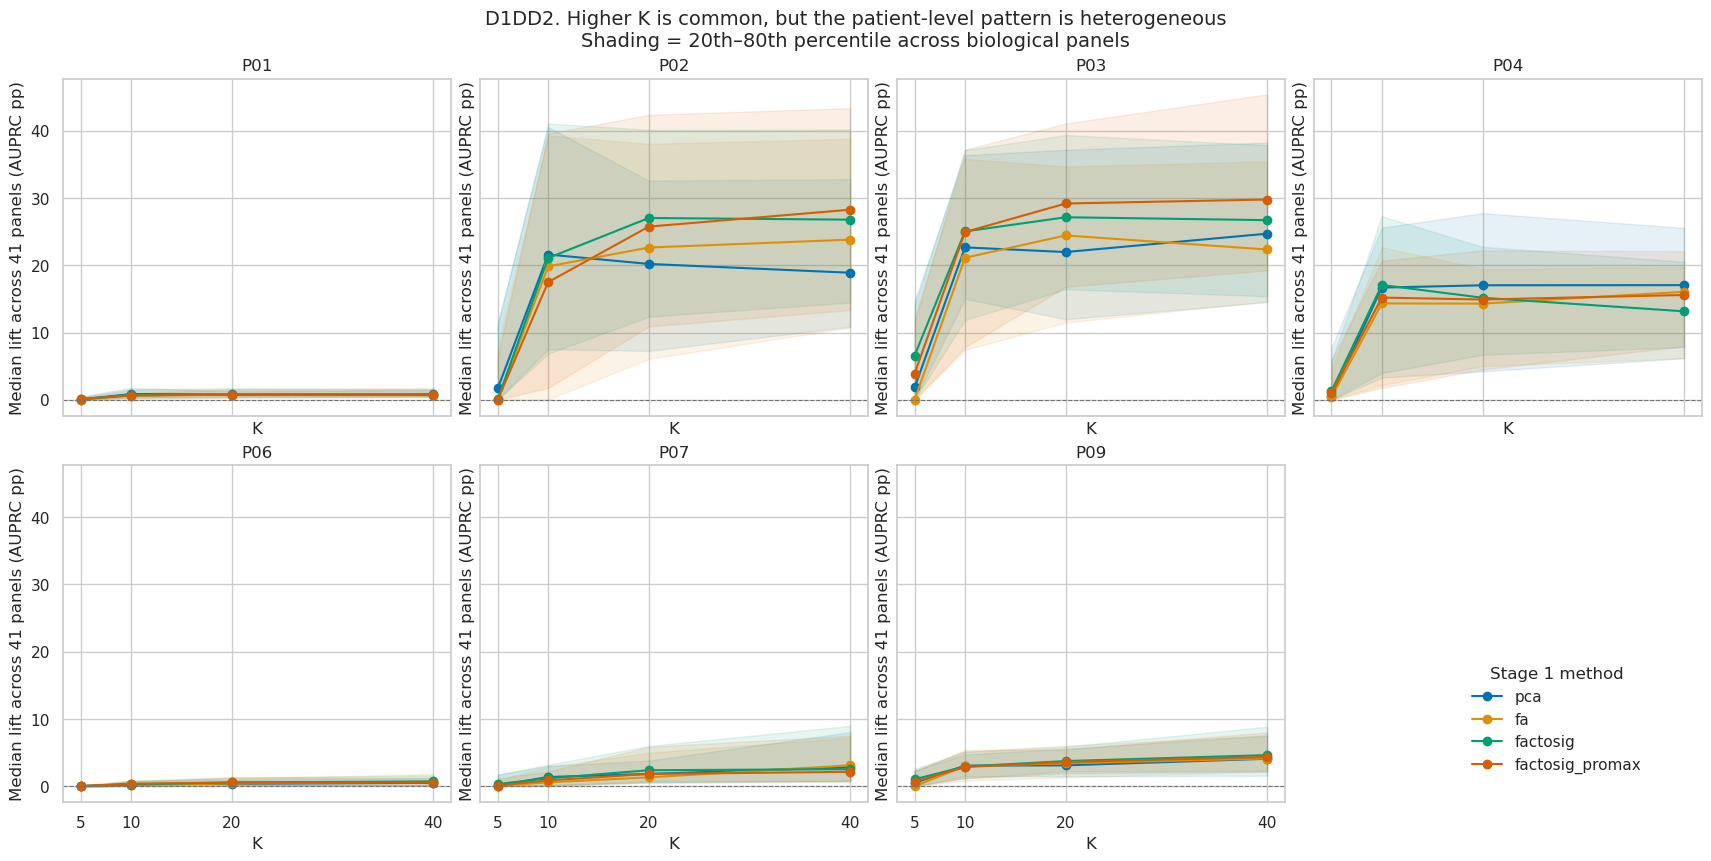

In [4]:
# D1DD2 — patient-specific central K trends across the 41 biological panels.
bio_patient_dr = atlas_patient.loc[
    atlas_patient["atlas_row_block"].eq("biological")
    & atlas_patient["stage1_method"].isin(METHOD_ORDER)
].copy()
bio_patient_dr["effective_k"] = bio_patient_dr["configuration"].str.extract(r"K=(\d+)")[0].astype(int)
patient_k_summary = (
    bio_patient_dr.groupby(["heldout_patient", "stage1_method", "effective_k"], observed=True)["heldout_lift_percentage_points"]
    .agg(median_across_panels="median", q20_across_panels=lambda values: values.quantile(0.20), q80_across_panels=lambda values: values.quantile(0.80))
    .reset_index()
)
write_csv(patient_k_summary, "d1dd_patient_k_summary_across_biological_panels.csv")

method_colors = dict(zip(METHOD_ORDER, sns.color_palette("colorblind", len(METHOD_ORDER))))
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5), sharex=True, sharey=True, constrained_layout=True)
for ax, patient_id in zip(axes.flat, SUPPORTED_PATIENTS):
    patient_summary = patient_k_summary.loc[patient_k_summary["heldout_patient"].eq(patient_id)]
    for method in METHOD_ORDER:
        method_df = patient_summary.loc[patient_summary["stage1_method"].eq(method)].sort_values("effective_k")
        ax.plot(method_df["effective_k"], method_df["median_across_panels"], marker="o", color=method_colors[method], label=method)
        ax.fill_between(
            method_df["effective_k"].to_numpy(),
            method_df["q20_across_panels"].to_numpy(),
            method_df["q80_across_panels"].to_numpy(),
            color=method_colors[method],
            alpha=0.10,
        )
    ax.axhline(0, color="0.45", lw=0.8, ls="--")
    ax.set_title(patient_id)
    ax.set_xticks(K_ORDER)
    ax.set_xlabel("K")
    ax.set_ylabel("Median lift across 41 panels (AUPRC pp)")
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower right", bbox_to_anchor=(0.97, 0.08), frameon=False, title="Stage 1 method")
fig.suptitle("D1DD2. Higher K is common, but the patient-level pattern is heterogeneous\nShading = 20th–80th percentile across biological panels", fontsize=14)
save_figure(fig, "D1DD2_patient_specific_k_trends_across_panels")
plt.show()

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_all_configuration_summaries.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_all_patient_lifts.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD3_hallmark_allograft_rejection_patient_configuration_heatmap.png


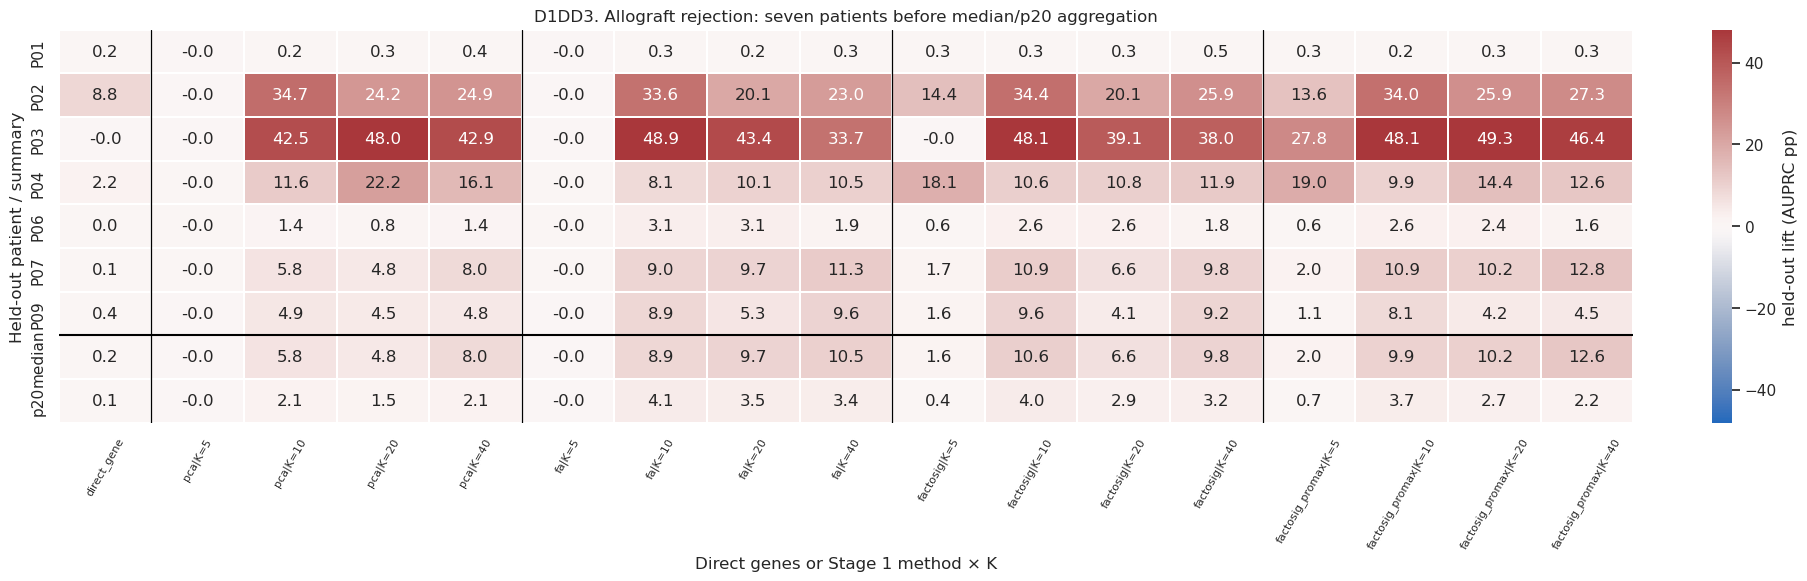

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD3_hallmark_apoptosis_patient_configuration_heatmap.png


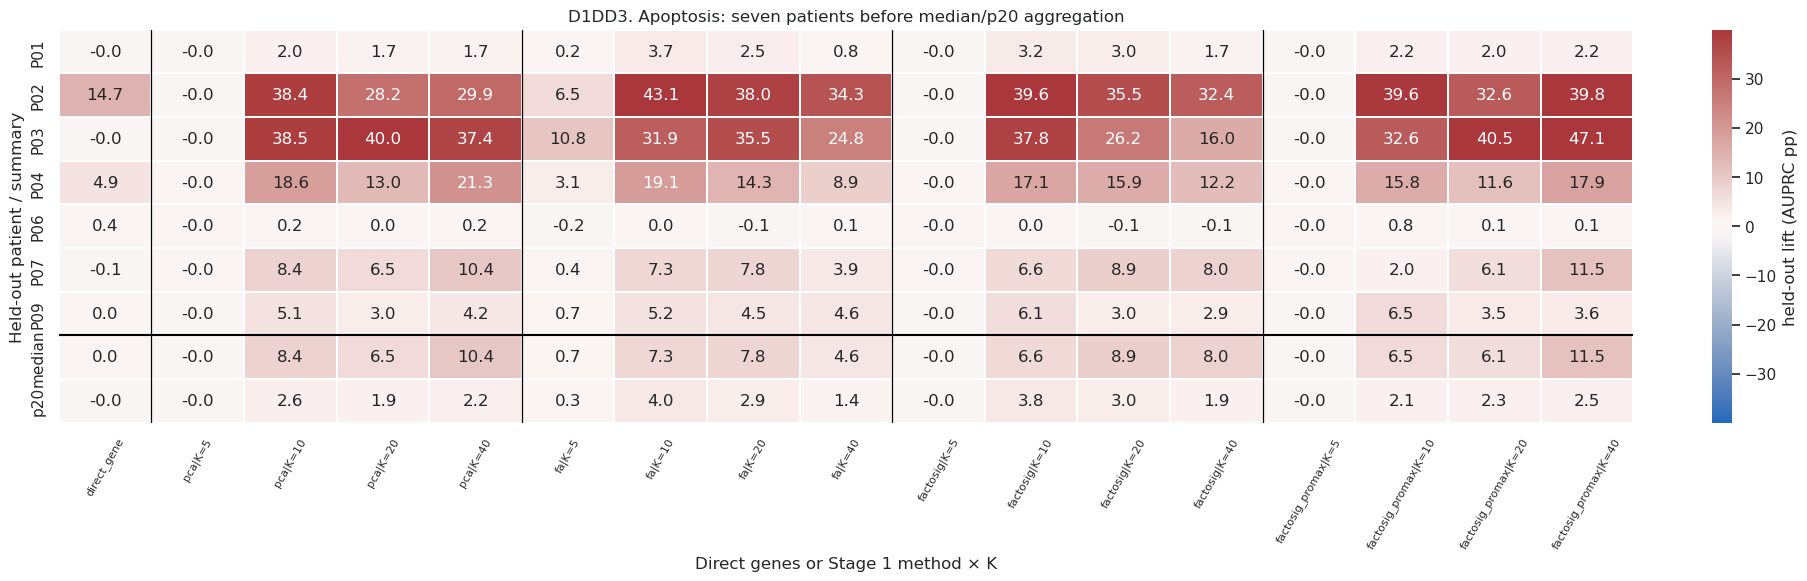

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD3_hallmark_tnfa_signaling_via_nfkb_patient_configuration_heatmap.png


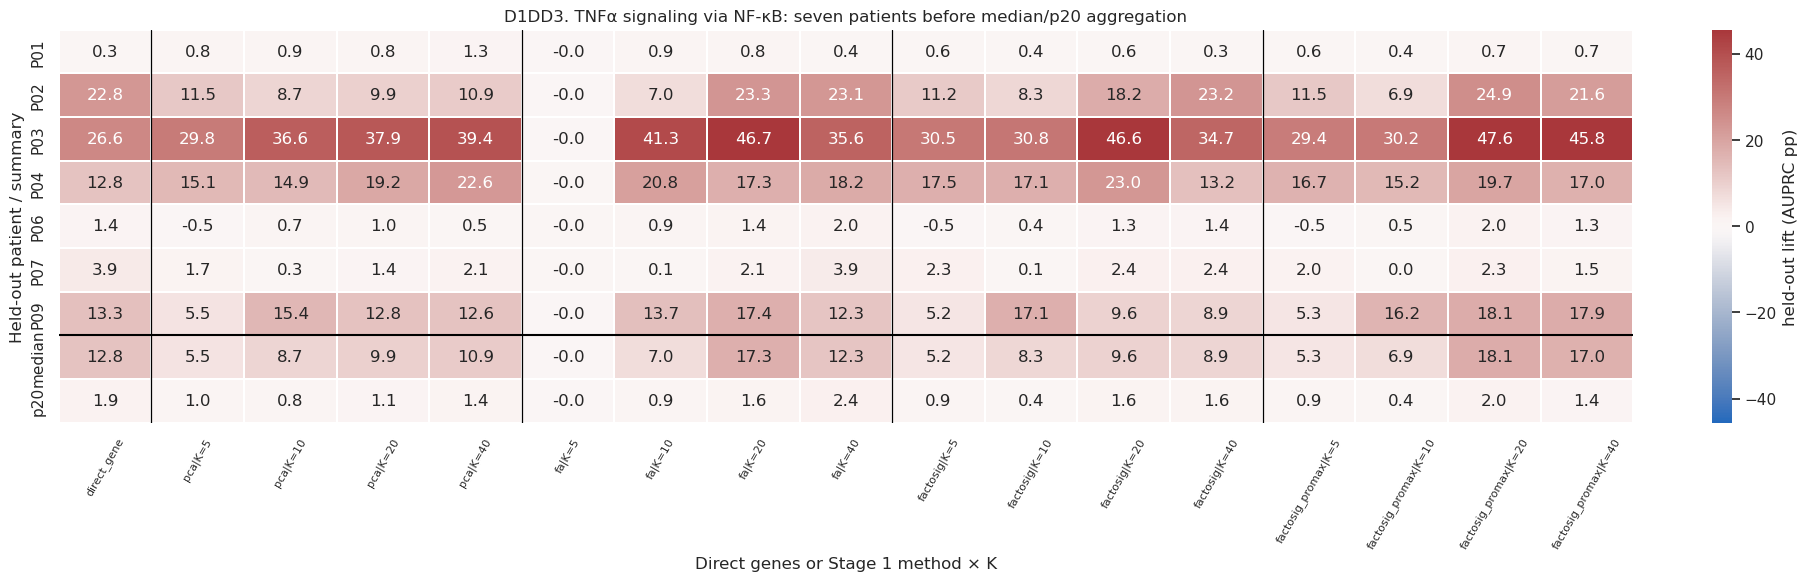

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_selected_vs_direct_summary.csv


,stage0_panel_id,panel,selected_configuration,selected_median_lift_pp,selected_p20_lift_pp,direct_median_lift_pp,direct_p20_lift_pp,selected_minus_direct_median_pp
0,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax|K=40,12.56,2.19,0.23,0.06,12.33
1,single_geneset__hallmark_apoptosis,Apoptosis,factosig_promax|K=40,11.52,2.48,0.00,-0.00,11.52
2,single_geneset__hallmark_tnfa_signaling_via_nfkb,TNFα signaling via NF-κB,factosig_promax|K=20,18.06,2.02,12.78,1.89,5.28


In [5]:
# D1DD3 — full patient × configuration maps for the three focus panels.
focus_ids = list(FOCUS)
focus_representation = atlas_representation.loc[atlas_representation["stage0_panel_id"].isin(focus_ids)].copy()
focus_patient = atlas_patient.loc[atlas_patient["stage0_panel_id"].isin(focus_ids)].copy()
focus_representation["median_lift_pp"] = 100 * focus_representation["patient_median_lift"]
focus_representation["p20_lift_pp"] = 100 * focus_representation["patient_p20_lift"]
write_csv(focus_representation, "d1dd_focus_panel_all_configuration_summaries.csv")
write_csv(focus_patient, "d1dd_focus_panel_all_patient_lifts.csv")

focus_summary_rows = []
for panel_id, spec in FOCUS.items():
    selected_config = spec["selected_configuration"]
    selected_row = focus_representation.loc[
        focus_representation["stage0_panel_id"].eq(panel_id)
        & focus_representation["configuration"].eq(selected_config)
    ].iloc[0]
    direct_row = focus_representation.loc[
        focus_representation["stage0_panel_id"].eq(panel_id)
        & focus_representation["configuration"].eq("direct_gene")
    ].iloc[0]
    focus_summary_rows.append(
        {
            "stage0_panel_id": panel_id,
            "panel": spec["label"],
            "selected_configuration": selected_config,
            "selected_median_lift_pp": 100 * selected_row["patient_median_lift"],
            "selected_p20_lift_pp": 100 * selected_row["patient_p20_lift"],
            "direct_median_lift_pp": 100 * direct_row["patient_median_lift"],
            "direct_p20_lift_pp": 100 * direct_row["patient_p20_lift"],
            "selected_minus_direct_median_pp": 100 * (selected_row["patient_median_lift"] - direct_row["patient_median_lift"]),
        }
    )

    patient_matrix = (
        focus_patient.loc[focus_patient["stage0_panel_id"].eq(panel_id)]
        .pivot(index="heldout_patient", columns="configuration", values="heldout_lift_percentage_points")
        .reindex(index=SUPPORTED_PATIENTS, columns=CONFIG_ORDER)
    )
    summary_matrix = pd.DataFrame(
        [patient_matrix.median(axis=0), patient_matrix.quantile(0.20, axis=0)],
        index=["median", "p20"],
    )
    plot_matrix = pd.concat([patient_matrix, summary_matrix])
    panel_vmax = max(float(np.nanquantile(np.abs(plot_matrix.to_numpy()), 0.98)), 3.0)
    fig, ax = plt.subplots(figsize=(18, 5.7), constrained_layout=True)
    sns.heatmap(
        plot_matrix,
        cmap=cmap,
        center=0,
        vmin=-panel_vmax,
        vmax=panel_vmax,
        annot=True,
        fmt=".1f",
        linewidths=0.35,
        linecolor="white",
        cbar_kws={"label": "held-out lift (AUPRC pp)"},
        ax=ax,
    )
    for boundary in [1, 5, 9, 13]:
        ax.axvline(boundary, color="black", lw=0.9)
    ax.axhline(len(SUPPORTED_PATIENTS), color="black", lw=1.5)
    ax.set_title(f"D1DD3. {spec['label']}: seven patients before median/p20 aggregation")
    ax.set_xlabel("Direct genes or Stage 1 method × K")
    ax.set_ylabel("Held-out patient / summary")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    save_figure(fig, f"D1DD3_{panel_id.replace('single_geneset__', '')}_patient_configuration_heatmap")
    plt.show()

focus_summary = pd.DataFrame(focus_summary_rows)
write_csv(focus_summary, "d1dd_focus_panel_selected_vs_direct_summary.csv")
display(focus_summary.style.format({column: "{:.2f}" for column in focus_summary if column.endswith("_pp")}))

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD4_focus_panel_median_and_p20_k_trajectories.png


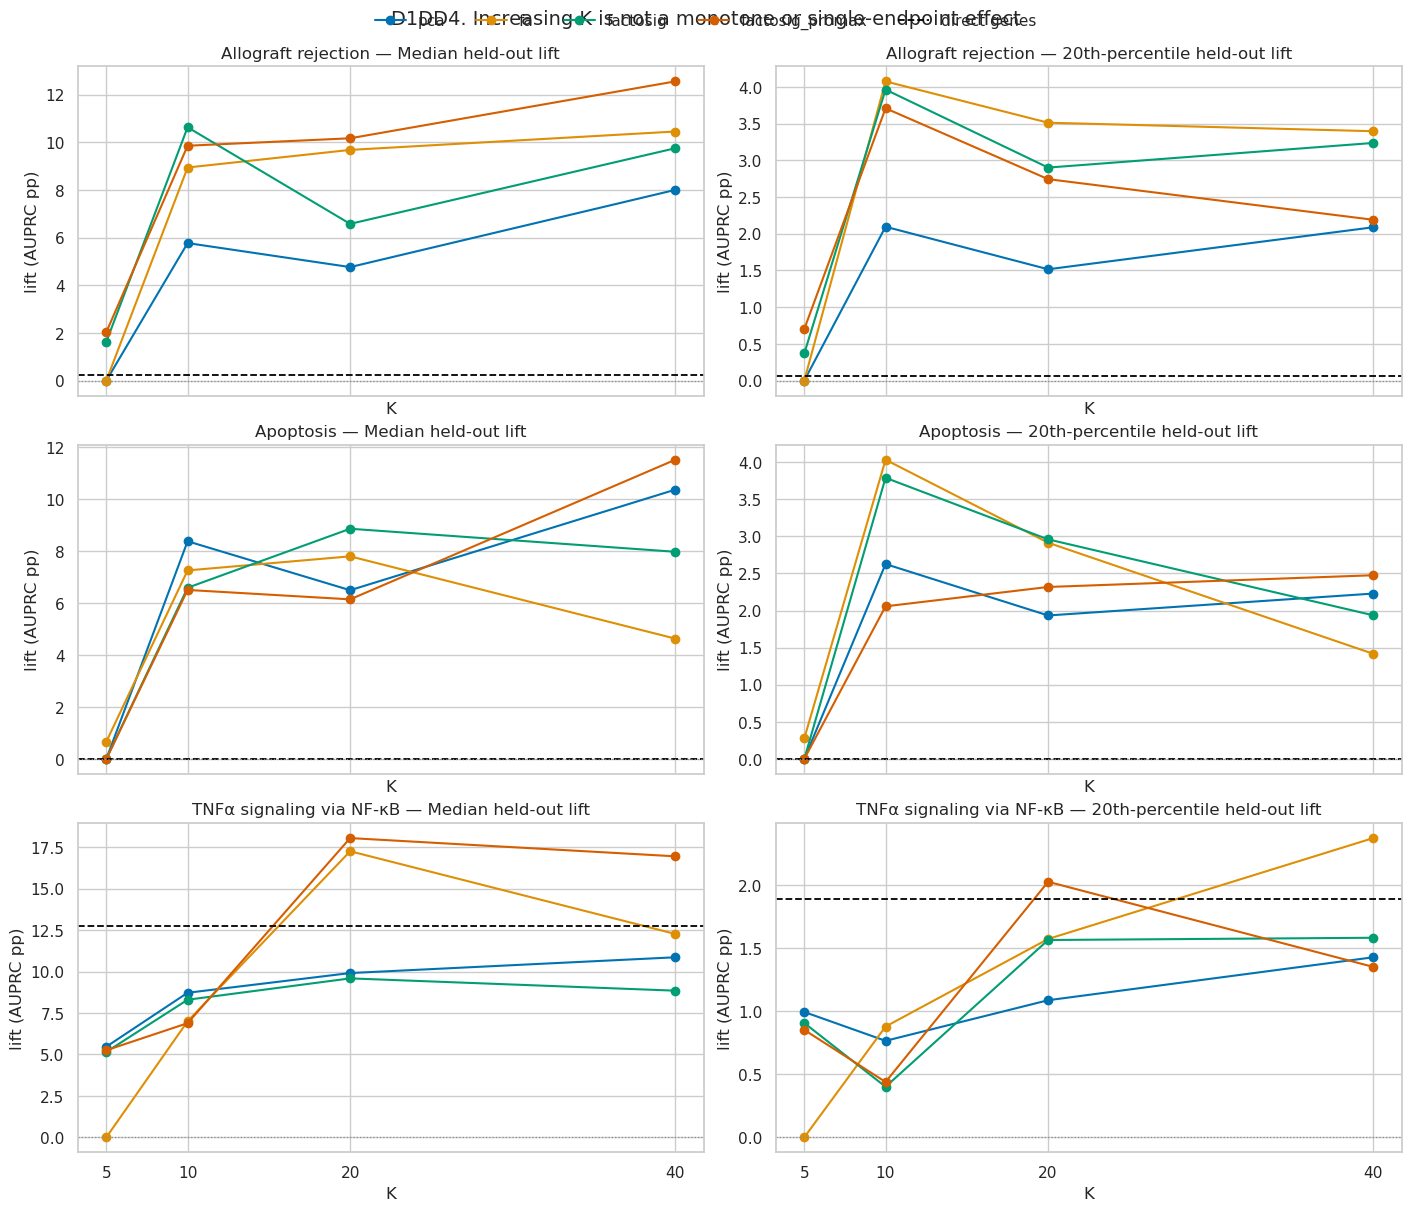

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD5_focus_panel_patient_paired_dr_vs_direct.png


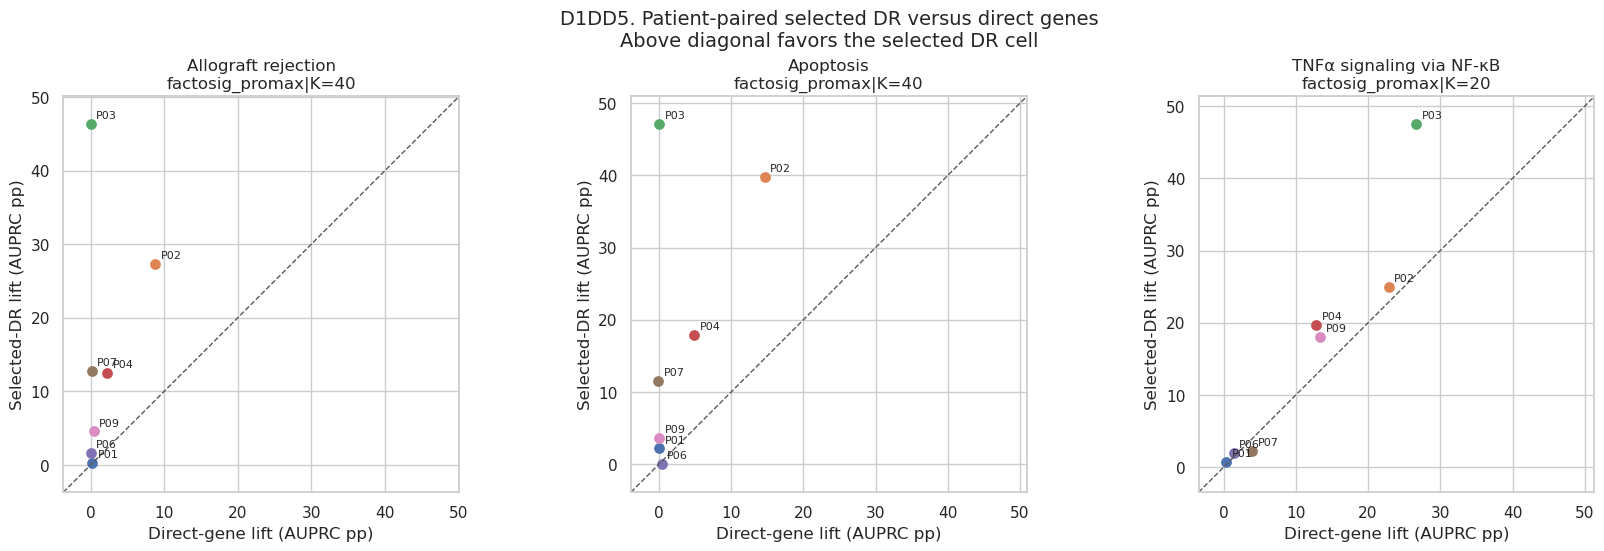

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_patient_paired_dr_vs_direct.csv


,stage0_panel_id,panel,heldout_patient,selected_configuration,selected_dr_lift_pp,direct_gene_lift_pp,selected_minus_direct_pp
0,single_geneset__hallmark_allograft_rejection,Allograft rejection,P01,factosig_promax|K=40,0.318195,2.288896e-01,0.089305
1,single_geneset__hallmark_allograft_rejection,Allograft rejection,P02,factosig_promax|K=40,27.288992,8.810677e+00,18.478316
2,single_geneset__hallmark_allograft_rejection,Allograft rejection,P03,factosig_promax|K=40,46.367362,-5.551115e-15,46.367362
3,single_geneset__hallmark_allograft_rejection,Allograft rejection,P04,factosig_promax|K=40,12.558608,2.227874e+00,10.330734
4,single_geneset__hallmark_allograft_rejection,Allograft rejection,P06,factosig_promax|K=40,1.602011,3.616066e-02,1.565851
5,single_geneset__hallmark_allograft_rejection,Allograft rejection,P07,factosig_promax|K=40,12.829278,1.436273e-01,12.685651
6,single_geneset__hallmark_allograft_rejection,Allograft rejection,P09,factosig_promax|K=40,4.545845,4.277098e-01,4.118135
7,single_geneset__hallmark_apoptosis,Apoptosis,P01,factosig_promax|K=40,2.187393,-4.770490e-15,2.187393
8,single_geneset__hallmark_apoptosis,Apoptosis,P02,factosig_promax|K=40,39.794806,1.465611e+01,25.138697
9,single_geneset__hallmark_apoptosis,Apoptosis,P03,factosig_promax|K=40,47.145199,-5.551115e-15,47.145199


In [6]:
# D1DD4 — median and p20 are different questions; D1DD5 — paired patients vs direct genes.
fig, axes = plt.subplots(len(FOCUS), 2, figsize=(14, 12), sharex=True, constrained_layout=True)
for row_index, (panel_id, spec) in enumerate(FOCUS.items()):
    panel_rows = focus_representation.loc[
        focus_representation["stage0_panel_id"].eq(panel_id)
        & focus_representation["stage1_method"].isin(METHOD_ORDER)
    ].copy()
    direct_row = focus_representation.loc[
        focus_representation["stage0_panel_id"].eq(panel_id)
        & focus_representation["configuration"].eq("direct_gene")
    ].iloc[0]
    for column_index, (metric, direct_metric, title) in enumerate([
        ("median_lift_pp", 100 * direct_row["patient_median_lift"], "Median held-out lift"),
        ("p20_lift_pp", 100 * direct_row["patient_p20_lift"], "20th-percentile held-out lift"),
    ]):
        ax = axes[row_index, column_index]
        for method in METHOD_ORDER:
            method_rows = panel_rows.loc[panel_rows["stage1_method"].eq(method)].sort_values("effective_k")
            ax.plot(method_rows["effective_k"], method_rows[metric], marker="o", color=method_colors[method], label=method)
        ax.axhline(direct_metric, color="black", ls="--", lw=1.3, label="direct genes")
        ax.axhline(0, color="0.55", ls=":", lw=0.9)
        ax.set_title(f"{spec['label']} — {title}")
        ax.set_xlabel("K")
        ax.set_ylabel("lift (AUPRC pp)")
        ax.set_xticks(K_ORDER)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=5, frameon=False)
fig.suptitle("D1DD4. Increasing K is not a monotone or single-endpoint effect", fontsize=14)
save_figure(fig, "D1DD4_focus_panel_median_and_p20_k_trajectories")
plt.show()

paired_rows = []
fig, axes = plt.subplots(1, len(FOCUS), figsize=(17, 5.4), constrained_layout=True)
for ax, (panel_id, spec) in zip(axes, FOCUS.items()):
    selected_config = spec["selected_configuration"]
    panel_long = focus_patient.loc[
        focus_patient["stage0_panel_id"].eq(panel_id)
        & focus_patient["configuration"].isin(["direct_gene", selected_config])
    ]
    paired = panel_long.pivot(index="heldout_patient", columns="configuration", values="heldout_lift_percentage_points").reindex(SUPPORTED_PATIENTS)
    for patient_id, row in paired.iterrows():
        paired_rows.append(
            {
                "stage0_panel_id": panel_id,
                "panel": spec["label"],
                "heldout_patient": patient_id,
                "selected_configuration": selected_config,
                "selected_dr_lift_pp": row[selected_config],
                "direct_gene_lift_pp": row["direct_gene"],
                "selected_minus_direct_pp": row[selected_config] - row["direct_gene"],
            }
        )
        ax.scatter(row["direct_gene"], row[selected_config], s=45)
        ax.annotate(patient_id, (row["direct_gene"], row[selected_config]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    limits = [float(np.nanmin(paired.to_numpy())), float(np.nanmax(paired.to_numpy()))]
    pad = max((limits[1] - limits[0]) * 0.08, 0.5)
    limits = [limits[0] - pad, limits[1] + pad]
    ax.plot(limits, limits, color="0.35", ls="--", lw=1)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"{spec['label']}\n{selected_config}")
    ax.set_xlabel("Direct-gene lift (AUPRC pp)")
    ax.set_ylabel("Selected-DR lift (AUPRC pp)")
fig.suptitle("D1DD5. Patient-paired selected DR versus direct genes\nAbove diagonal favors the selected DR cell", fontsize=14)
save_figure(fig, "D1DD5_focus_panel_patient_paired_dr_vs_direct")
plt.show()

paired_focus = pd.DataFrame(paired_rows)
write_csv(paired_focus, "d1dd_focus_panel_patient_paired_dr_vs_direct.csv")
display(paired_focus)

## 4. Do allograft rejection and apoptosis share the same genes?

The relevant comparison is the **covered** Stage 0 gene list actually present after cohort filtering, not the original unfiltered MSigDB list. A small membership overlap does not rule out correlated expression programs, shared cell-type structure, or donor/recipient confounding. It only tests whether the two panels are literally using many of the same genes.

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_covered_gene_membership.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_allograft_apoptosis_shared_genes.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD6_focus_panel_covered_gene_overlap.png


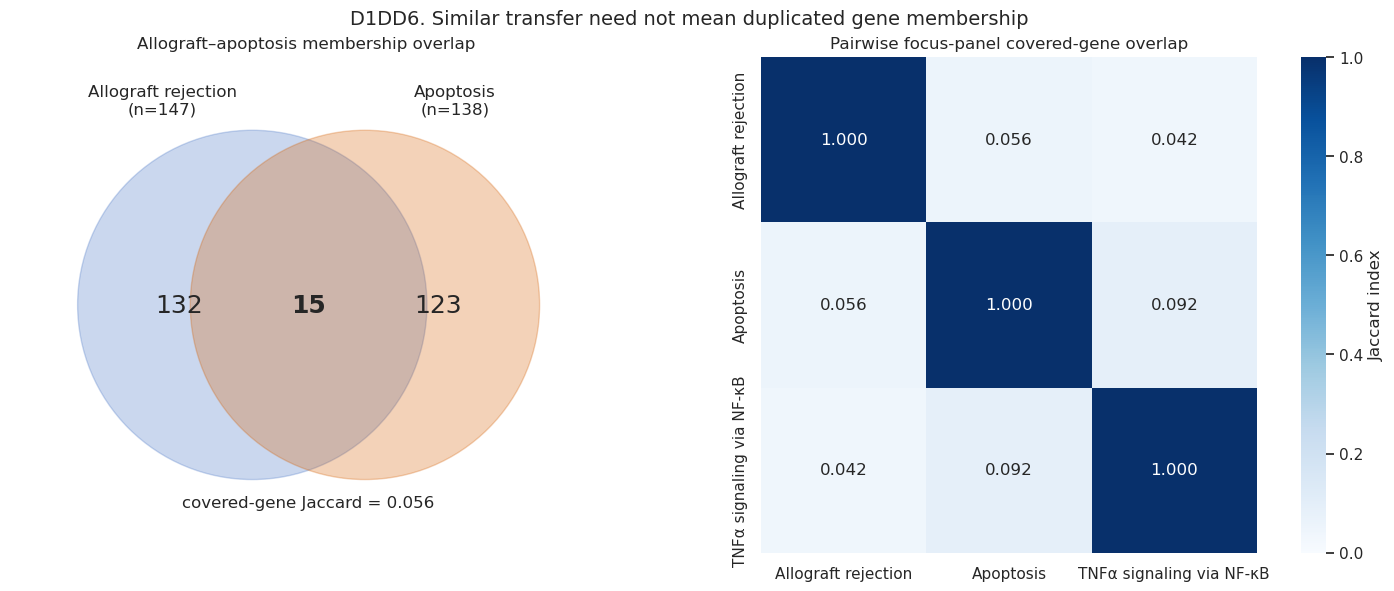

Allograft ∩ apoptosis: 15 genes / 270 union genes; Jaccard=0.0556
BCL10, BRCA1, CCND2, CD2, EREG, F2, F2R, FAS, IFNGR1, IL18, IL1B, TAP1, TGFB2, TIMP1, TNF


In [7]:
# D1DD6 — covered-gene overlap for the focus panels.
gene_sets = {}
for panel_id, spec in FOCUS.items():
    gene_path = EXP_DIR / "preprocessing" / "panels" / "stage0_panel_genes" / f"{panel_id}.json"
    gene_sets[panel_id] = set(json.loads(gene_path.read_text())["genes"])

allograft_id, apoptosis_id, tnfa_id = list(FOCUS)
allograft_genes = gene_sets[allograft_id]
apoptosis_genes = gene_sets[apoptosis_id]
shared_allograft_apoptosis = sorted(allograft_genes & apoptosis_genes)
union_size = len(allograft_genes | apoptosis_genes)
jaccard_value = len(shared_allograft_apoptosis) / union_size

all_focus_genes = sorted(set().union(*gene_sets.values()))
membership = pd.DataFrame({
    "gene": all_focus_genes,
    **{FOCUS[panel_id]["label"]: [gene in genes for gene in all_focus_genes] for panel_id, genes in gene_sets.items()},
})
write_csv(membership, "d1dd_focus_panel_covered_gene_membership.csv")
write_csv(pd.DataFrame({"shared_gene": shared_allograft_apoptosis}), "d1dd_allograft_apoptosis_shared_genes.csv")

labels = [FOCUS[panel_id]["label"] for panel_id in FOCUS]
jaccard_matrix = pd.DataFrame(index=labels, columns=labels, dtype=float)
for left_id, left_label in zip(FOCUS, labels):
    for right_id, right_label in zip(FOCUS, labels):
        left, right = gene_sets[left_id], gene_sets[right_id]
        jaccard_matrix.loc[left_label, right_label] = len(left & right) / len(left | right)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), constrained_layout=True)
ax = axes[0]
ax.add_patch(Circle((0.43, 0.52), 0.31, alpha=0.28, color="#4472C4"))
ax.add_patch(Circle((0.63, 0.52), 0.31, alpha=0.28, color="#D55E00"))
ax.text(0.30, 0.52, str(len(allograft_genes - apoptosis_genes)), ha="center", va="center", fontsize=18)
ax.text(0.53, 0.52, str(len(shared_allograft_apoptosis)), ha="center", va="center", fontsize=18, fontweight="bold")
ax.text(0.76, 0.52, str(len(apoptosis_genes - allograft_genes)), ha="center", va="center", fontsize=18)
ax.text(0.27, 0.86, f"Allograft rejection\n(n={len(allograft_genes)})", ha="center")
ax.text(0.79, 0.86, f"Apoptosis\n(n={len(apoptosis_genes)})", ha="center")
ax.text(0.53, 0.16, f"covered-gene Jaccard = {jaccard_value:.3f}", ha="center")
ax.set_xlim(0, 1.05)
ax.set_ylim(0.08, 0.96)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Allograft–apoptosis membership overlap")

sns.heatmap(jaccard_matrix, vmin=0, vmax=1, cmap="Blues", annot=True, fmt=".3f", square=True, cbar_kws={"label": "Jaccard index"}, ax=axes[1])
axes[1].set_title("Pairwise focus-panel covered-gene overlap")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
fig.suptitle("D1DD6. Similar transfer need not mean duplicated gene membership", fontsize=14)
save_figure(fig, "D1DD6_focus_panel_covered_gene_overlap")
plt.show()

print(f"Allograft ∩ apoptosis: {len(shared_allograft_apoptosis)} genes / {union_size} union genes; Jaccard={jaccard_value:.4f}")
print(", ".join(shared_allograft_apoptosis))

## 5. Label-free Stage 1 structure: PCA variance and FA common variance

“Useful without the target label” must be stated carefully. A label-free diagnostic can show how much expression structure a component captures, whether it is stable, and whether additional rank still models covariance. It cannot show that the structure is useful for malignancy prediction.

- **PCA:** `explained_variance_ratio` has its usual meaning; cumulative values are fractions of total standardized expression variance.
- **FA:** there is no PCA-equivalent ordered explained-variance ratio. Here `sum(loadings²) / n_genes` is reported as the fraction of standardized variance attributed to the fitted common-factor model. For the focus scree plots, K=40 factors are sorted by loading energy solely for display.
- **Do not compare the two percentages as identical estimands.** PCA partitions total variance; FA partitions common versus feature-specific variance under a model.

D1DD7 reads each independently fitted K artifact. D1DD8 inspects the K=40 focus fits. Neither plot makes the independent FA fits nested.

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_pca_fa_label_free_variance_summary.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD7_knowledge_panel_pca_fa_variance_by_k.png


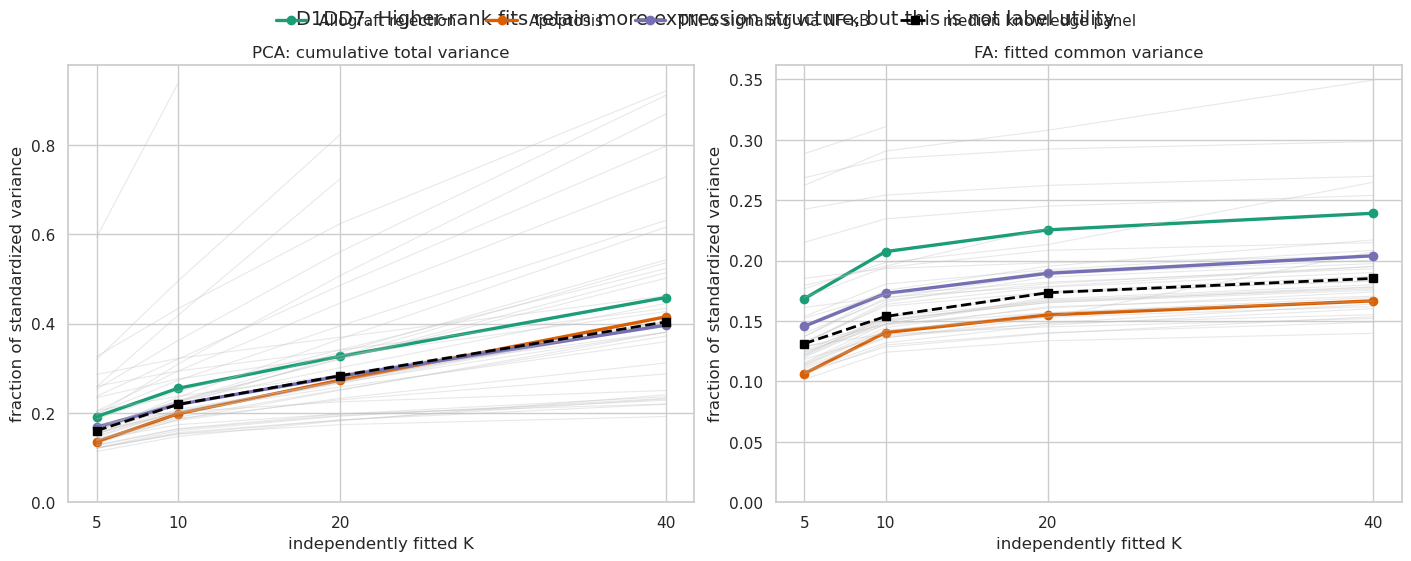

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD8_focus_panel_pca_fa_component_scree.png


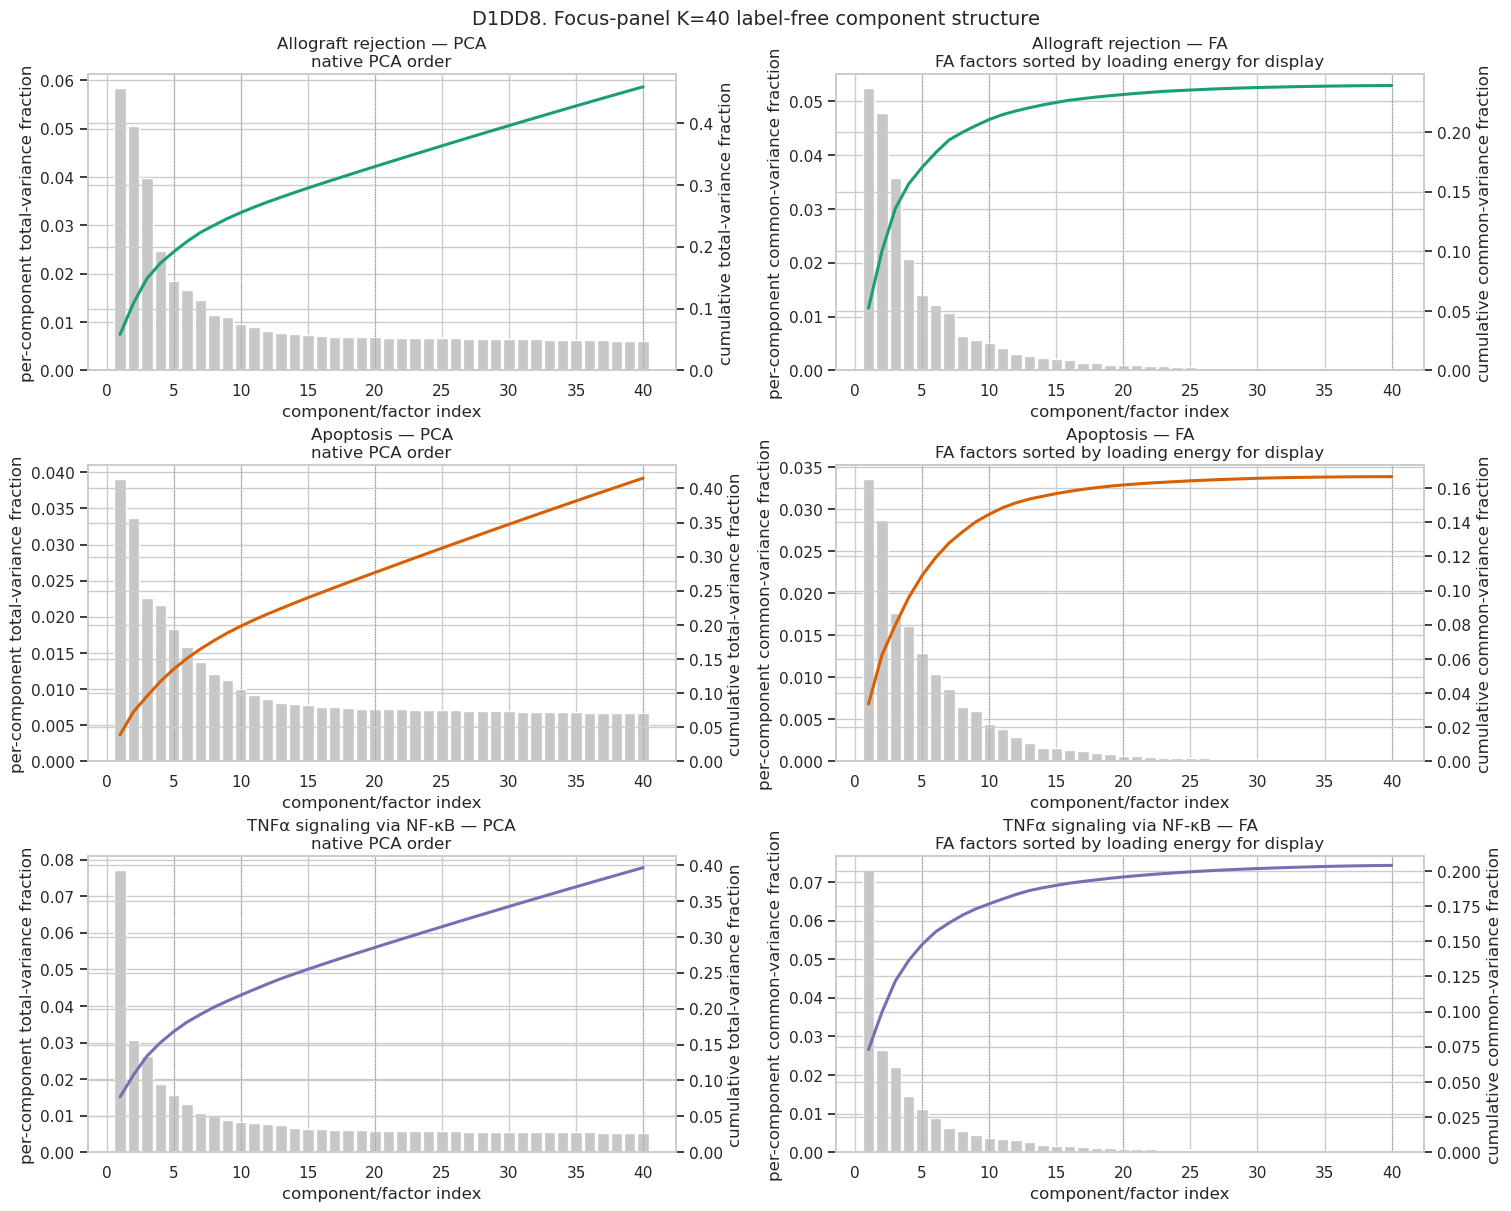

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_pca_fa_component_scree.csv


PosixPath('/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_pca_fa_component_scree.csv')

In [8]:
# D1DD7/8 — existing unsupervised diagnostics; no label is read in these calculations.
knowledge_ids = set(panel_meta.loc[~panel_meta["panel_class"].eq("Data-driven HVG control"), "stage0_panel_id"])
variance_records = []
variance_rows = atlas_representation.loc[
    atlas_representation["stage0_panel_id"].isin(knowledge_ids)
    & atlas_representation["stage1_method"].isin(["pca", "fa"])
].drop_duplicates(["stage0_panel_id", "stage1_method", "effective_k"])

for row in variance_rows.itertuples():
    k = int(row.effective_k)
    diagnostics_path = EXP_DIR / "stage1_dr" / f"panel_id={row.stage0_panel_id}" / f"method={row.stage1_method}" / f"k={k}" / "seed=42" / "diagnostics.json"
    if not diagnostics_path.exists():
        continue
    diagnostics = json.loads(diagnostics_path.read_text())
    if row.stage1_method == "pca":
        fraction = float(np.sum(diagnostics["extras"]["uns"]["explained_variance_ratio"]))
        metric = "PCA cumulative total-variance fraction"
    else:
        fraction = float(np.sum(diagnostics["loading_ss"]) / int(row.n_covered_genes))
        metric = "FA fitted common-variance fraction"
    variance_records.append(
        {
            "stage0_panel_id": row.stage0_panel_id,
            "panel_label_with_genes": row.panel_label_with_genes,
            "panel_class": str(panel_meta.set_index("stage0_panel_id").loc[row.stage0_panel_id, "panel_class"]),
            "stage1_method": row.stage1_method,
            "effective_k": k,
            "n_covered_genes": int(row.n_covered_genes),
            "variance_fraction": fraction,
            "metric": metric,
            "diagnostics_path": str(diagnostics_path.relative_to(EXP_DIR)),
        }
    )
variance_summary = pd.DataFrame(variance_records)
write_csv(variance_summary, "d1dd_pca_fa_label_free_variance_summary.csv")

focus_colors = dict(zip(FOCUS, sns.color_palette("Dark2", len(FOCUS))))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, constrained_layout=True)
for ax, method, title in [
    (axes[0], "pca", "PCA: cumulative total variance"),
    (axes[1], "fa", "FA: fitted common variance"),
]:
    method_df = variance_summary.loc[variance_summary["stage1_method"].eq(method)]
    for panel_id, group in method_df.groupby("stage0_panel_id"):
        group = group.sort_values("effective_k")
        if panel_id in FOCUS:
            ax.plot(group["effective_k"], group["variance_fraction"], marker="o", lw=2.4, color=focus_colors[panel_id], label=FOCUS[panel_id]["label"])
        else:
            ax.plot(group["effective_k"], group["variance_fraction"], color="0.75", alpha=0.35, lw=0.8)
    median_curve = method_df.groupby("effective_k")["variance_fraction"].median().reindex(K_ORDER)
    ax.plot(K_ORDER, median_curve, color="black", marker="s", lw=2, ls="--", label="median knowledge panel")
    ax.set_title(title)
    ax.set_xlabel("independently fitted K")
    ax.set_ylabel("fraction of standardized variance")
    ax.set_xticks(K_ORDER)
    ax.set_ylim(bottom=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=4, frameon=False)
fig.suptitle("D1DD7. Higher-rank fits retain more expression structure, but this is not label utility", fontsize=14)
save_figure(fig, "D1DD7_knowledge_panel_pca_fa_variance_by_k")
plt.show()

fig, axes = plt.subplots(len(FOCUS), 2, figsize=(15, 12), constrained_layout=True)
focus_scree_records = []
for row_index, (panel_id, spec) in enumerate(FOCUS.items()):
    n_genes = int(panel_meta.set_index("stage0_panel_id").loc[panel_id, "n_covered_genes"])
    for column_index, method in enumerate(["pca", "fa"]):
        path = EXP_DIR / "stage1_dr" / f"panel_id={panel_id}" / f"method={method}" / "k=40" / "seed=42" / "diagnostics.json"
        diagnostics = json.loads(path.read_text())
        if method == "pca":
            component_fraction = np.asarray(diagnostics["extras"]["uns"]["explained_variance_ratio"], dtype=float)
            ordering_note = "native PCA order"
            metric_label = "total-variance fraction"
        else:
            component_fraction = np.sort(np.asarray(diagnostics["loading_ss"], dtype=float) / n_genes)[::-1]
            ordering_note = "FA factors sorted by loading energy for display"
            metric_label = "common-variance fraction"
        cumulative = np.cumsum(component_fraction)
        component_index = np.arange(1, len(component_fraction) + 1)
        ax = axes[row_index, column_index]
        ax.bar(component_index, component_fraction, color="0.78", width=0.85, label="per component")
        twin = ax.twinx()
        twin.plot(component_index, cumulative, color=focus_colors[panel_id], lw=2.2, label="cumulative")
        for k in K_ORDER:
            ax.axvline(k, color="0.55", lw=0.7, ls=":")
        ax.set_title(f"{spec['label']} — {method.upper()}\n{ordering_note}")
        ax.set_xlabel("component/factor index")
        ax.set_ylabel(f"per-component {metric_label}")
        twin.set_ylabel(f"cumulative {metric_label}")
        twin.set_ylim(bottom=0)
        for idx, value in enumerate(component_fraction, start=1):
            focus_scree_records.append({"stage0_panel_id": panel_id, "panel": spec["label"], "stage1_method": method, "display_component_index": idx, "component_variance_fraction": value, "cumulative_variance_fraction": cumulative[idx - 1], "ordering_note": ordering_note})
fig.suptitle("D1DD8. Focus-panel K=40 label-free component structure", fontsize=14)
save_figure(fig, "D1DD8_focus_panel_pca_fa_component_scree")
plt.show()
write_csv(pd.DataFrame(focus_scree_records), "d1dd_focus_panel_pca_fa_component_scree.csv")

## 6. What a one-score-per-set baseline means

For a panel containing many genes, a pathway-scoring method reduces each cell to **one scalar activity score for the whole set**:

- **AUCell** ranks genes within a cell and measures how strongly the set is recovered near the top of that ranking.
- **UCell** uses a rank-based Mann–Whitney-U-style score, usually truncating the ranking, to produce a composition-robust per-cell score.
- **ssGSEA** ranks genes within one sample/cell and computes a running-sum enrichment contrast between genes inside and outside the set.

The output shape for one geneset is therefore `n_cells × 1`. By contrast, PCA/FA/FactoSig at K=40 produces `n_cells × 40`: the classifier may use separate axes for lineage, activation, stress, donor origin, or multiple mechanistic subprograms inside one broad list.

“If the one-score baseline matches K=40” means that, under the same patient-held-out evaluation, one overall set-activity ranking predicts about as well as the 40-coordinate representation. Then the extra latent axes have not shown added predictive value beyond a conventional pathway-activity summary. It does **not** prove the latent factors are mathematically identical to GSEA.

If K=40 wins reproducibly, that supports—but does not mechanistically prove—the idea that the broad geneset contains multiple predictive covariance patterns. Those axes still need loading, cell-type, surface-protein, and biological review.

D1DD9 implements a cheap first-pass `mean z-score` one-score proxy from the same covered genes. It is not UCell/AUCell/ssGSEA and is labeled accordingly; a rank-based implementation remains a future matched comparator.

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_mean_z_one_score_lopo.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_one_score_direct_dr_comparison.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD9_focus_panel_one_score_vs_direct_and_dr.png


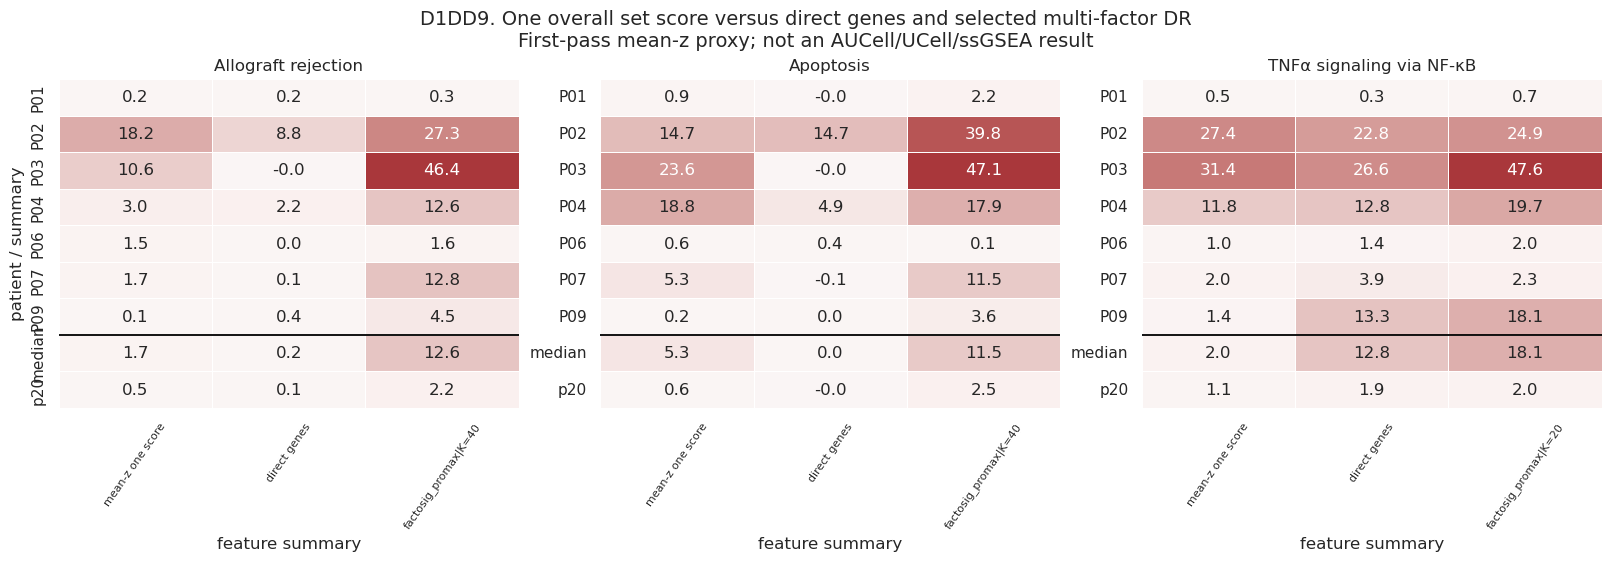

In [9]:
# D1DD9 — a one-dimensional mean-z pathway-score proxy under LOPO.
direct_stage0 = pd.read_csv(SOURCE_PATHS["direct_stage0_scorecard"], low_memory=False)
reference_prediction_path = EXP_DIR / direct_stage0.loc[direct_stage0["stage2_status"].eq("ok"), "stage2_predictions_path"].iloc[0]
reference_prediction = pd.read_csv(reference_prediction_path, index_col=0)
cell_ids_reference = reference_prediction.index.astype(str)
y_reference = reference_prediction["y_true"].astype(int).to_numpy()
patient_reference = reference_prediction["patient"].astype(str).to_numpy()
assert len(reference_prediction) == 60_118

one_score_rows = []
for panel_id, spec in FOCUS.items():
    direct_row = direct_stage0.loc[direct_stage0["stage0_panel_id"].eq(panel_id)].iloc[0]
    features = load_npz(EXP_DIR / direct_row["features_path"]).toarray().astype(np.float32, copy=False)
    assert features.shape[0] == len(reference_prediction)
    mean_z_score = features.mean(axis=1)
    del features
    for patient_id in sorted(np.unique(patient_reference)):
        train_mask = patient_reference != patient_id
        heldout_mask = patient_reference == patient_id
        y_train = y_reference[train_mask]
        y_heldout = y_reference[heldout_mask]
        if len(np.unique(y_train)) < 2 or len(np.unique(y_heldout)) < 2:
            continue
        scaler = StandardScaler().fit(mean_z_score[train_mask, None])
        train_score = scaler.transform(mean_z_score[train_mask, None])
        heldout_score = scaler.transform(mean_z_score[heldout_mask, None])
        model = LogisticRegression(C=1.0, penalty="l2", solver="liblinear", class_weight="balanced", max_iter=5000, random_state=42)
        model.fit(train_score, y_train)
        probability = model.predict_proba(heldout_score)[:, 1]
        prevalence = float(y_heldout.mean())
        auprc = float(average_precision_score(y_heldout, probability))
        one_score_rows.append(
            {
                "stage0_panel_id": panel_id,
                "panel": spec["label"],
                "heldout_patient": patient_id,
                "score_definition": "mean of globally z-scored covered genes",
                "stage2_model": "one-feature balanced L2 logistic regression, C=1",
                "heldout_auprc": auprc,
                "patient_prevalence": prevalence,
                "heldout_lift_percentage_points": 100 * (auprc - prevalence),
                "training_coefficient": float(model.coef_.ravel()[0]),
            }
        )
one_score = pd.DataFrame(one_score_rows)
one_score_supported = one_score.loc[one_score["heldout_patient"].isin(SUPPORTED_PATIENTS)].copy()
write_csv(one_score, "d1dd_focus_panel_mean_z_one_score_lopo.csv")

comparator_rows = []
for panel_id, spec in FOCUS.items():
    selected_config = spec["selected_configuration"]
    for label, frame in [
        ("mean-z one score", one_score_supported.loc[one_score_supported["stage0_panel_id"].eq(panel_id)]),
        ("direct genes", focus_patient.loc[focus_patient["stage0_panel_id"].eq(panel_id) & focus_patient["configuration"].eq("direct_gene")]),
        (selected_config, focus_patient.loc[focus_patient["stage0_panel_id"].eq(panel_id) & focus_patient["configuration"].eq(selected_config)]),
    ]:
        for row in frame.itertuples():
            comparator_rows.append({"stage0_panel_id": panel_id, "panel": spec["label"], "heldout_patient": row.heldout_patient, "feature_summary": label, "heldout_lift_percentage_points": row.heldout_lift_percentage_points})
comparator = pd.DataFrame(comparator_rows)
write_csv(comparator, "d1dd_focus_panel_one_score_direct_dr_comparison.csv")

fig, axes = plt.subplots(1, len(FOCUS), figsize=(16, 5.5), constrained_layout=True)
for ax, (panel_id, spec) in zip(axes, FOCUS.items()):
    panel_comparison = comparator.loc[comparator["stage0_panel_id"].eq(panel_id)]
    order = ["mean-z one score", "direct genes", spec["selected_configuration"]]
    matrix = panel_comparison.pivot(index="heldout_patient", columns="feature_summary", values="heldout_lift_percentage_points").reindex(index=SUPPORTED_PATIENTS, columns=order)
    matrix.loc["median"] = matrix.median(axis=0)
    matrix.loc["p20"] = matrix.iloc[: len(SUPPORTED_PATIENTS)].quantile(0.20, axis=0)
    local_vmax = max(float(np.nanmax(np.abs(matrix.to_numpy()))), 3.0)
    sns.heatmap(matrix, cmap=cmap, center=0, vmin=-local_vmax, vmax=local_vmax, annot=True, fmt=".1f", linewidths=0.4, cbar=False, ax=ax)
    ax.axhline(len(SUPPORTED_PATIENTS), color="black", lw=1.3)
    ax.set_title(spec["label"])
    ax.set_xlabel("feature summary")
    ax.set_ylabel("patient / summary" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=55, labelsize=8)
fig.suptitle("D1DD9. One overall set score versus direct genes and selected multi-factor DR\nFirst-pass mean-z proxy; not an AUCell/UCell/ssGSEA result", fontsize=14)
save_figure(fig, "D1DD9_focus_panel_one_score_vs_direct_and_dr")
plt.show()

## 7. Cell-level ranking-error audit

AUPRC evaluates an entire score ranking and does not define a positive/negative cutoff. The saved selected-LOPO coefficient cache also omits intercepts, although intercepts do not affect ranking. To inspect cells without inventing a 0.5 threshold, this notebook labels the top `n_malignant` cells within each held-out patient as rank-positive. This prevalence-matched cutoff uses the held-out labels and is therefore **post hoc and descriptive**:

- true positive / false negative partition the known malignant cells;
- false positive / true negative partition the known normal cells;
- these labels describe where ranking errors occur, not prospective diagnostic calls.

The selected DR score is reconstructed exactly from the saved Stage 1 scores, fold-specific scaling, and fold-specific coefficients, then checked against the stored patient AUPRC.

Available contextual fields include predicted cell type and confidence, pseudotime, source (donor/recipient), sample/timepoint, days from stem-cell transplant, days from relapse, RNA/ADT library size, detected features, and mitochondrial fraction. The AnnData contains 170 CITE-seq ADT markers. It does **not** contain a detailed treatment-regimen history, so `Days from SCT` and `Days.from.Relapse` are collection-timing context—not substitutes for treatment annotation.

In [10]:
# Reconstruct selected-DR held-out rankings and attach cell metadata.
cohort = ad.read_h5ad(SOURCE_PATHS["cohort_cache"], backed="r")
obs = cohort.obs.copy()
obs.index = obs.index.astype(str)
assert cohort.n_obs == 60_118
assert obs.index.equals(pd.Index(cell_ids_reference)), "Filtered cohort cache and Stage 1/2 row order differ"
assert np.array_equal(obs["patient"].astype(str).to_numpy(), patient_reference)
assert np.array_equal(obs["CN.label"].astype(str).eq("cancer").astype(int).to_numpy(), y_reference)

metadata_columns = [
    "patient", "CN.label", "source", "predicted.annotation", "predicted.annotation.score",
    "predicted.pseudotime", "predicted.pseudotime.score", "Time", "sample", "library", "batch",
    "Days from SCT", "Days.from.Relapse", "nCount_RNA", "nFeature_RNA", "nCount_ADT",
    "nFeature_ADT", "percent.mt",
]
missing_metadata = [column for column in metadata_columns if column not in obs]
assert not missing_metadata, missing_metadata

selected_coefficients = pd.read_pickle(SOURCE_PATHS["selected_lopo_coefficients"], compression="gzip")
selected_coefficients = selected_coefficients.loc[selected_coefficients["selection_roles"].str.contains("global_selected")].copy()
selected_coefficients["coefficient"] = pd.to_numeric(selected_coefficients["coefficient"], errors="coerce").fillna(0.0)

prediction_frames = []
reconstruction_rows = []
for panel_id, spec in FOCUS.items():
    method, k_text = spec["selected_configuration"].split("|K=")
    k = int(k_text)
    representation_id = f"{panel_id}|dr|{method}|{k}|42"
    score_path = EXP_DIR / "stage1_dr" / f"panel_id={panel_id}" / f"method={method}" / f"k={k}" / "seed=42" / "scores.npy"
    scores = np.load(score_path)
    assert scores.shape == (60_118, k)
    representation_coefficients = selected_coefficients.loc[selected_coefficients["representation_id"].eq(representation_id)]
    assert representation_coefficients["heldout_patient"].nunique() == 13
    feature_ids = [f"factor_{index:03d}" for index in range(1, k + 1)]

    for patient_id in SUPPORTED_PATIENTS:
        train_mask = patient_reference != patient_id
        heldout_mask = patient_reference == patient_id
        scaler = StandardScaler().fit(scores[train_mask])
        heldout_scores = scaler.transform(scores[heldout_mask])
        coefficient_rows = representation_coefficients.loc[representation_coefficients["heldout_patient"].astype(str).eq(patient_id)]
        coefficient_vector = coefficient_rows.set_index("feature_id")["coefficient"].reindex(feature_ids).fillna(0.0).to_numpy(dtype=float)
        linear_score = heldout_scores @ coefficient_vector
        y_heldout = y_reference[heldout_mask]
        reconstructed_ap = float(average_precision_score(y_heldout, linear_score))
        expected_ap = float(
            focus_patient.loc[
                focus_patient["representation_id"].eq(representation_id)
                & focus_patient["heldout_patient"].eq(patient_id),
                "heldout_auprc",
            ].iloc[0]
        )
        absolute_error = abs(reconstructed_ap - expected_ap)
        assert absolute_error < 2e-5, (representation_id, patient_id, reconstructed_ap, expected_ap)

        n_malignant = int(y_heldout.sum())
        rank_positive = np.zeros(len(linear_score), dtype=bool)
        rank_positive[np.argsort(-linear_score, kind="mergesort")[:n_malignant]] = True
        error_group = np.select(
            [
                (y_heldout == 1) & rank_positive,
                (y_heldout == 1) & ~rank_positive,
                (y_heldout == 0) & rank_positive,
                (y_heldout == 0) & ~rank_positive,
            ],
            ["TP", "FN", "FP", "TN"],
            default="unknown",
        )
        heldout_meta = obs.loc[heldout_mask, metadata_columns].copy()
        heldout_meta.insert(0, "cell_id", heldout_meta.index.astype(str))
        heldout_meta["stage0_panel_id"] = panel_id
        heldout_meta["panel"] = spec["label"]
        heldout_meta["representation_id"] = representation_id
        heldout_meta["configuration"] = spec["selected_configuration"]
        heldout_meta["linear_score"] = linear_score
        heldout_meta["within_patient_score_percentile"] = pd.Series(linear_score).rank(method="average", pct=True).to_numpy()
        heldout_meta["rank_positive"] = rank_positive
        heldout_meta["rank_error_group"] = error_group
        prediction_frames.append(heldout_meta.reset_index(drop=True))
        reconstruction_rows.append(
            {
                "representation_id": representation_id,
                "panel": spec["label"],
                "heldout_patient": patient_id,
                "expected_auprc": expected_ap,
                "reconstructed_auprc_without_intercept": reconstructed_ap,
                "absolute_error": absolute_error,
                "n_malignant_rank_positive": n_malignant,
                "n_nonzero_coefficients": int(np.sum(np.abs(coefficient_vector) > 1e-12)),
            }
        )

cell_predictions = pd.concat(prediction_frames, ignore_index=True)
reconstruction_audit = pd.DataFrame(reconstruction_rows)
write_csv(reconstruction_audit, "d1dd_selected_dr_cell_score_reconstruction_audit.csv")
write_csv(cell_predictions, "d1dd_selected_dr_supported_patient_cell_rank_audit.csv.gz", compression="gzip")
print("Maximum AUPRC reconstruction error:", reconstruction_audit["absolute_error"].max())
print("Cell × focus-panel audit rows:", len(cell_predictions))
display(reconstruction_audit)

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_selected_dr_cell_score_reconstruction_audit.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_selected_dr_supported_patient_cell_rank_audit.csv.gz
Maximum AUPRC reconstruction error: 3.114511812341014e-08
Cell × focus-panel audit rows: 118041


,representation_id,panel,heldout_patient,expected_auprc,reconstructed_auprc_without_intercept,absolute_error,n_malignant_rank_positive,n_nonzero_coefficients
0,single_geneset__hallmark_allograft_rejection|dr|factosig_promax|40|42,Allograft rejection,P01,0.006976,0.006976,3.469447e-18,45,18
1,single_geneset__hallmark_allograft_rejection|dr|factosig_promax|40|42,Allograft rejection,P02,0.417213,0.417213,0.000000e+00,211,18
2,single_geneset__hallmark_allograft_rejection|dr|factosig_promax|40|42,Allograft rejection,P03,0.789415,0.789415,0.000000e+00,758,19
3,single_geneset__hallmark_allograft_rejection|dr|factosig_promax|40|42,Allograft rejection,P04,0.216012,0.216012,2.775558e-17,102,17
4,single_geneset__hallmark_allograft_rejection|dr|factosig_promax|40|42,Allograft rejection,P06,0.029521,0.029521,3.469447e-17,44,18
5,single_geneset__hallmark_allograft_rejection|dr|factosig_promax|40|42,Allograft rejection,P07,0.138361,0.138361,5.551115e-17,22,19
6,single_geneset__hallmark_allograft_rejection|dr|factosig_promax|40|42,Allograft rejection,P09,0.067355,0.067355,3.114512e-08,375,19
7,single_geneset__hallmark_apoptosis|dr|factosig_promax|40|42,Apoptosis,P01,0.025668,0.025668,4.857226e-17,45,40
8,single_geneset__hallmark_apoptosis|dr|factosig_promax|40|42,Apoptosis,P02,0.542271,0.542271,0.000000e+00,211,40
9,single_geneset__hallmark_apoptosis|dr|factosig_promax|40|42,Apoptosis,P03,0.797193,0.797193,0.000000e+00,758,40


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_rank_matched_confusion_by_panel_patient.csv


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD10_rank_matched_error_overview.png


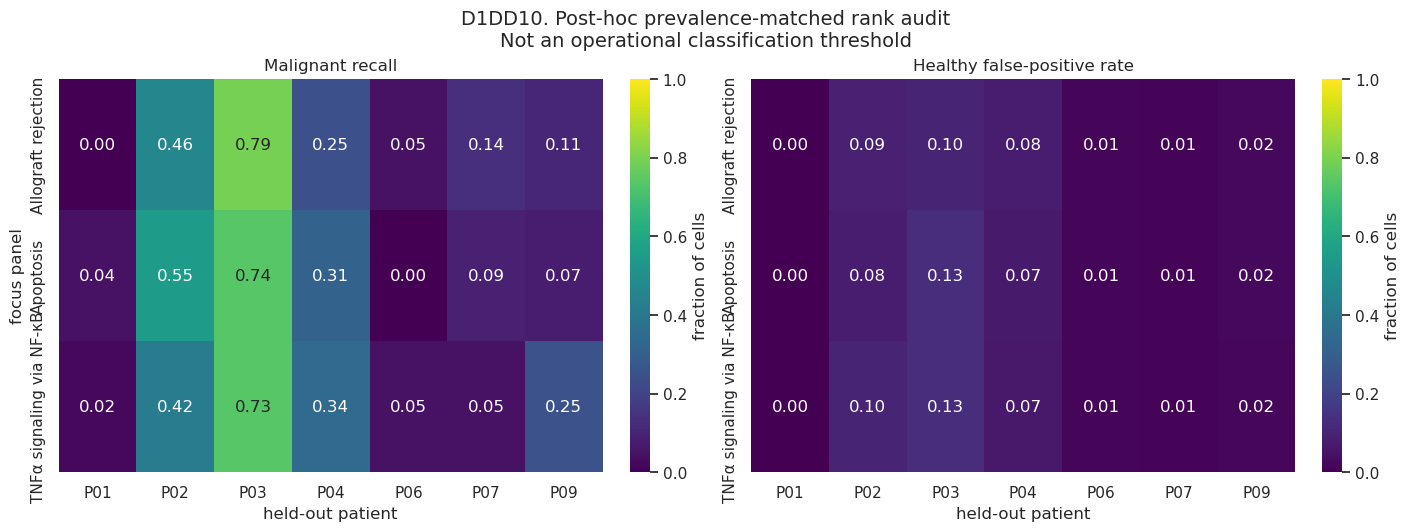

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_rank_error_by_panel_patient_celltype.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD11_rank_error_by_patient_celltype.png


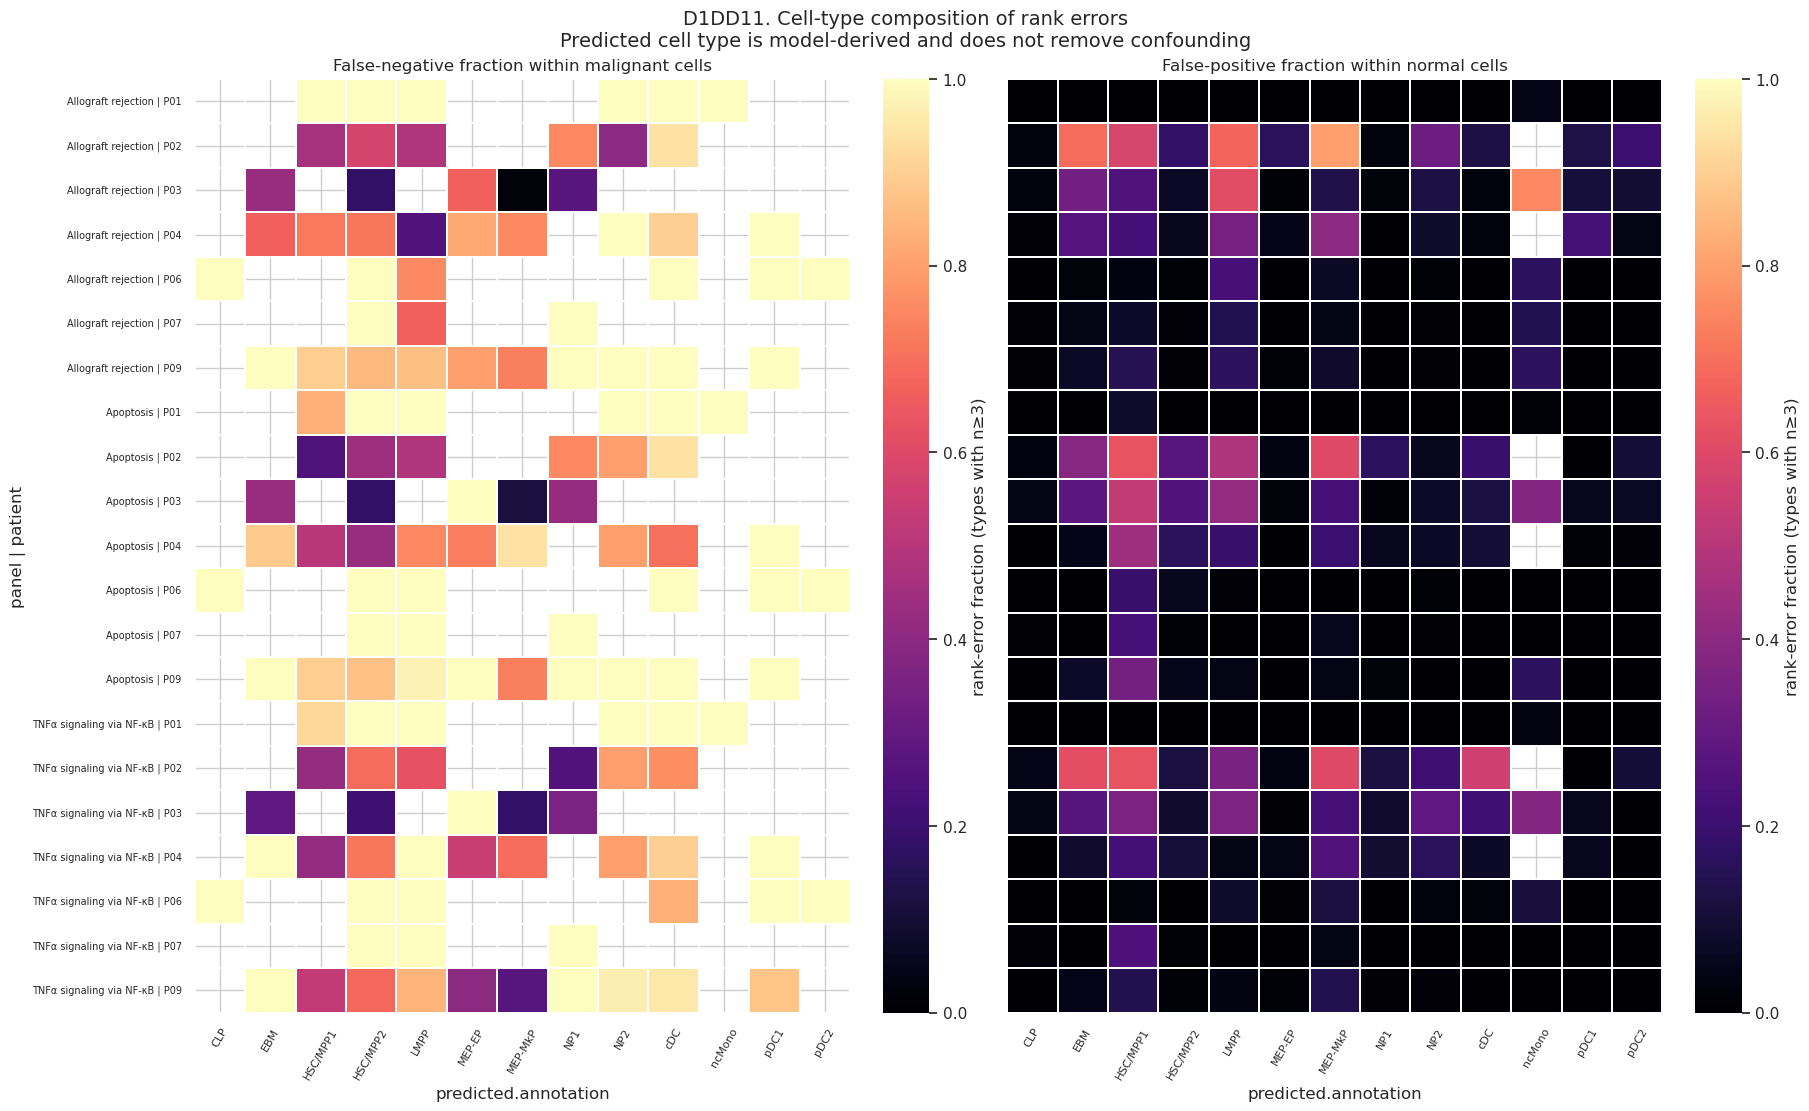

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_supported_patient_collection_context.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_cell_metadata_medians_by_rank_error_group.csv


,patient,samples,collection_labels,days_from_sct,days_from_relapse,sources,batches,libraries
0,P01,P01_MRD_2,MRD_2,228.0,-91.0,donor;recipient,E09P,P1;P2
1,P02,P02_MRD_2,MRD_2,122.0,-28.0,donor;recipient,E09P,P1;P2
2,P03,P03_MRD_2,MRD_2,694.0,-111.0,donor;recipient,E09P,P1;P2
3,P04,P04_MRD,MRD,176.0,-118.0,donor;recipient,E11P,P1;P2
4,P06,P06_MRD,MRD,76.0,-107.0,donor;recipient,E11P,P1;P2
5,P07,P07_MRD,MRD,87.0,-92.0,donor;recipient,E14P,P1;P2
6,P09,P09_MRD;P09_MRD_2;P09_MRD_3;P09_MRD_4,MRD;MRD_2;MRD_3;MRD_4,137.0;324.0;429.0;611.0,-112.0;-294.0;-399.0;-586.0,donor;recipient,E17P;E19P,P1;P2


In [11]:
# D1DD10/11 — where rank errors occur by patient and predicted cell type.
confusion_counts = (
    cell_predictions.groupby(["stage0_panel_id", "panel", "patient", "rank_error_group"], observed=True)
    .size()
    .unstack("rank_error_group", fill_value=0)
    .reset_index()
)
for column in ["TP", "FN", "FP", "TN"]:
    if column not in confusion_counts:
        confusion_counts[column] = 0
confusion_counts["malignant_recall_at_rank_matched_cutoff"] = confusion_counts["TP"] / (confusion_counts["TP"] + confusion_counts["FN"])
confusion_counts["healthy_false_positive_rate_at_rank_matched_cutoff"] = confusion_counts["FP"] / (confusion_counts["FP"] + confusion_counts["TN"])
write_csv(confusion_counts, "d1dd_rank_matched_confusion_by_panel_patient.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
for ax, metric, title in [
    (axes[0], "malignant_recall_at_rank_matched_cutoff", "Malignant recall"),
    (axes[1], "healthy_false_positive_rate_at_rank_matched_cutoff", "Healthy false-positive rate"),
]:
    matrix = confusion_counts.pivot(index="panel", columns="patient", values=metric).reindex(index=[spec["label"] for spec in FOCUS.values()], columns=SUPPORTED_PATIENTS)
    sns.heatmap(matrix, vmin=0, vmax=1, cmap="viridis", annot=True, fmt=".2f", cbar_kws={"label": "fraction of cells"}, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("held-out patient")
    ax.set_ylabel("focus panel" if ax is axes[0] else "")
fig.suptitle("D1DD10. Post-hoc prevalence-matched rank audit\nNot an operational classification threshold", fontsize=14)
save_figure(fig, "D1DD10_rank_matched_error_overview")
plt.show()

celltype_error = cell_predictions.assign(
    is_rank_error=lambda frame: frame["rank_error_group"].isin(["FN", "FP"]),
    truth_class=lambda frame: np.where(frame["CN.label"].astype(str).eq("cancer"), "malignant", "normal"),
).groupby(
    ["stage0_panel_id", "panel", "patient", "truth_class", "predicted.annotation"], observed=True
).agg(n_cells=("cell_id", "size"), n_rank_errors=("is_rank_error", "sum")).reset_index()
celltype_error["rank_error_rate"] = celltype_error["n_rank_errors"] / celltype_error["n_cells"]
celltype_error.loc[celltype_error["n_cells"].lt(3), "rank_error_rate"] = np.nan
write_csv(celltype_error, "d1dd_rank_error_by_panel_patient_celltype.csv")

row_order = [f"{spec['label']} | {patient}" for spec in FOCUS.values() for patient in SUPPORTED_PATIENTS]
celltype_error["panel_patient"] = celltype_error["panel"] + " | " + celltype_error["patient"].astype(str)
celltype_order = sorted(cell_predictions["predicted.annotation"].astype(str).unique())
fig, axes = plt.subplots(1, 2, figsize=(18, 11), sharey=True, constrained_layout=True)
for ax, truth_class, title in [
    (axes[0], "malignant", "False-negative fraction within malignant cells"),
    (axes[1], "normal", "False-positive fraction within normal cells"),
]:
    matrix = celltype_error.loc[celltype_error["truth_class"].eq(truth_class)].pivot(index="panel_patient", columns="predicted.annotation", values="rank_error_rate").reindex(index=row_order, columns=celltype_order)
    sns.heatmap(matrix, vmin=0, vmax=1, cmap="magma", linewidths=0.2, linecolor="white", cbar_kws={"label": "rank-error fraction (types with n≥3)"}, ax=ax)
    for boundary in [7, 14]:
        ax.axhline(boundary, color="white", lw=1.5)
    ax.set_title(title)
    ax.set_xlabel("predicted.annotation")
    ax.set_ylabel("panel | patient" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("D1DD11. Cell-type composition of rank errors\nPredicted cell type is model-derived and does not remove confounding", fontsize=14)
save_figure(fig, "D1DD11_rank_error_by_patient_celltype")
plt.show()


def join_unique(values: pd.Series) -> str:
    return ";".join(sorted({str(value) for value in values.dropna()}))

patient_context = (
    obs.loc[obs["patient"].astype(str).isin(SUPPORTED_PATIENTS)]
    .groupby("patient", observed=True)
    .agg(
        samples=("sample", join_unique),
        collection_labels=("Time", join_unique),
        days_from_sct=("Days from SCT", join_unique),
        days_from_relapse=("Days.from.Relapse", join_unique),
        sources=("source", join_unique),
        batches=("batch", join_unique),
        libraries=("library", join_unique),
    )
    .reset_index()
)
write_csv(patient_context, "d1dd_supported_patient_collection_context.csv")

continuous_metadata = ["predicted.annotation.score", "predicted.pseudotime", "predicted.pseudotime.score", "nCount_RNA", "nFeature_RNA", "nCount_ADT", "nFeature_ADT", "percent.mt"]
metadata_by_error = cell_predictions.groupby(["stage0_panel_id", "panel", "patient", "rank_error_group"], observed=True)[continuous_metadata].median().reset_index()
write_csv(metadata_by_error, "d1dd_cell_metadata_medians_by_rank_error_group.csv")
display(patient_context)

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD12_P01_cell_rank_celltype_adt_audit.png


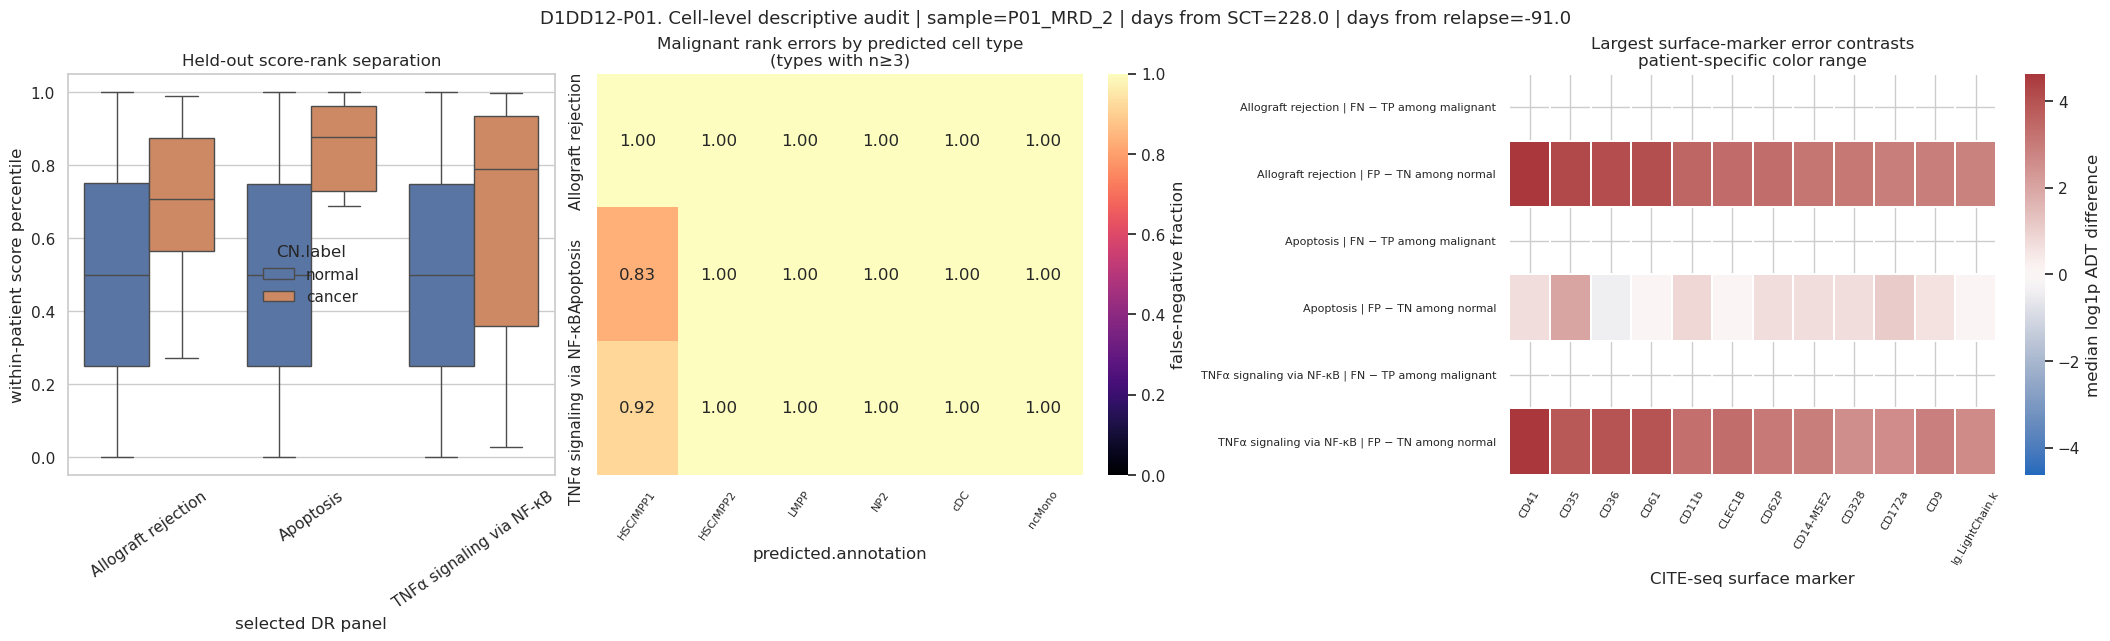

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD12_P02_cell_rank_celltype_adt_audit.png


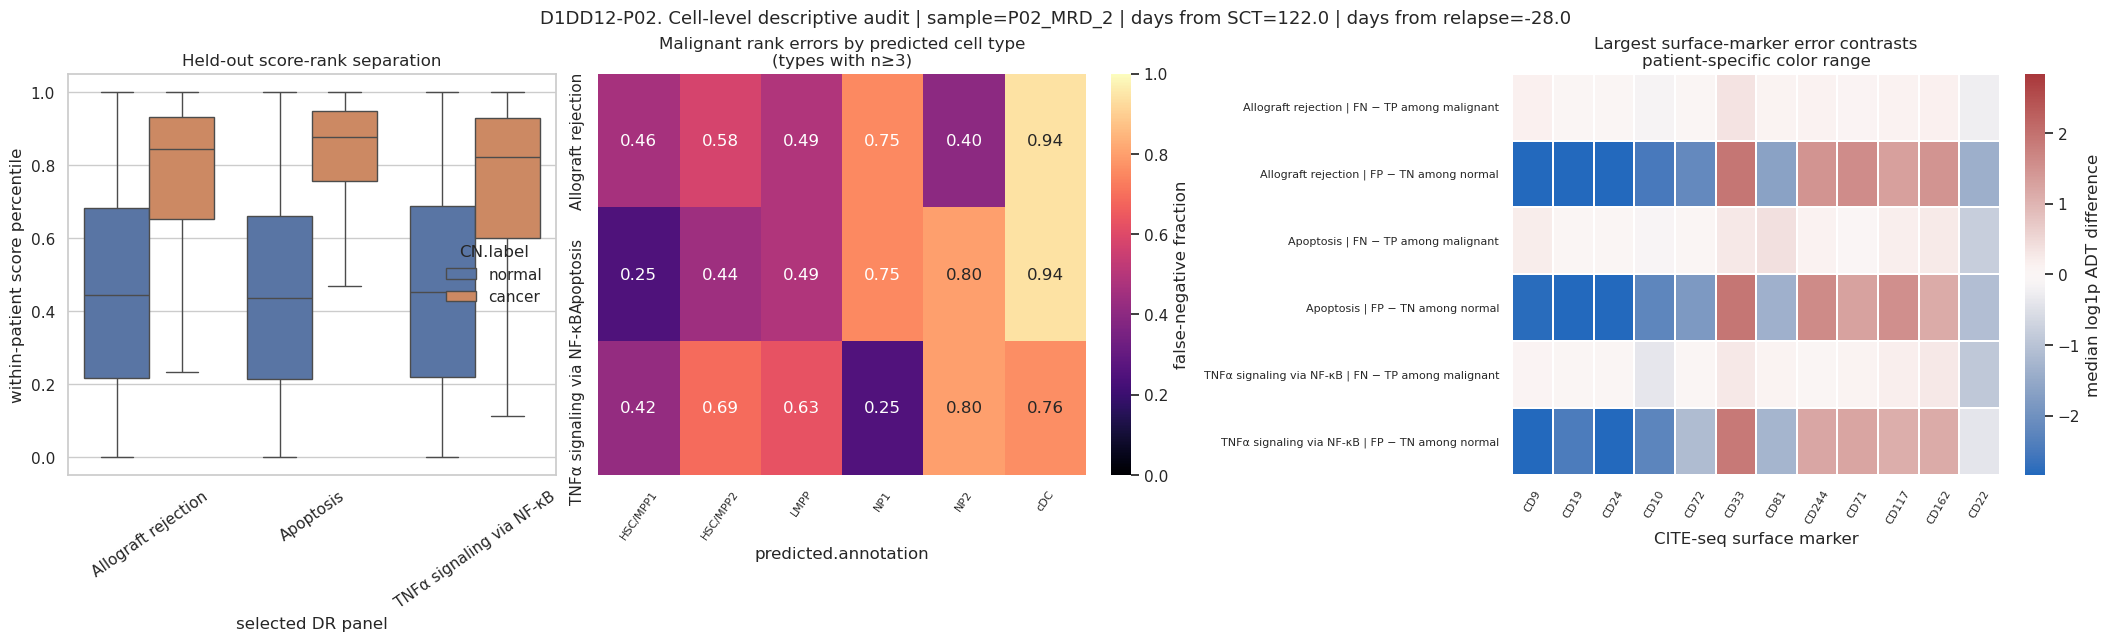

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD12_P03_cell_rank_celltype_adt_audit.png


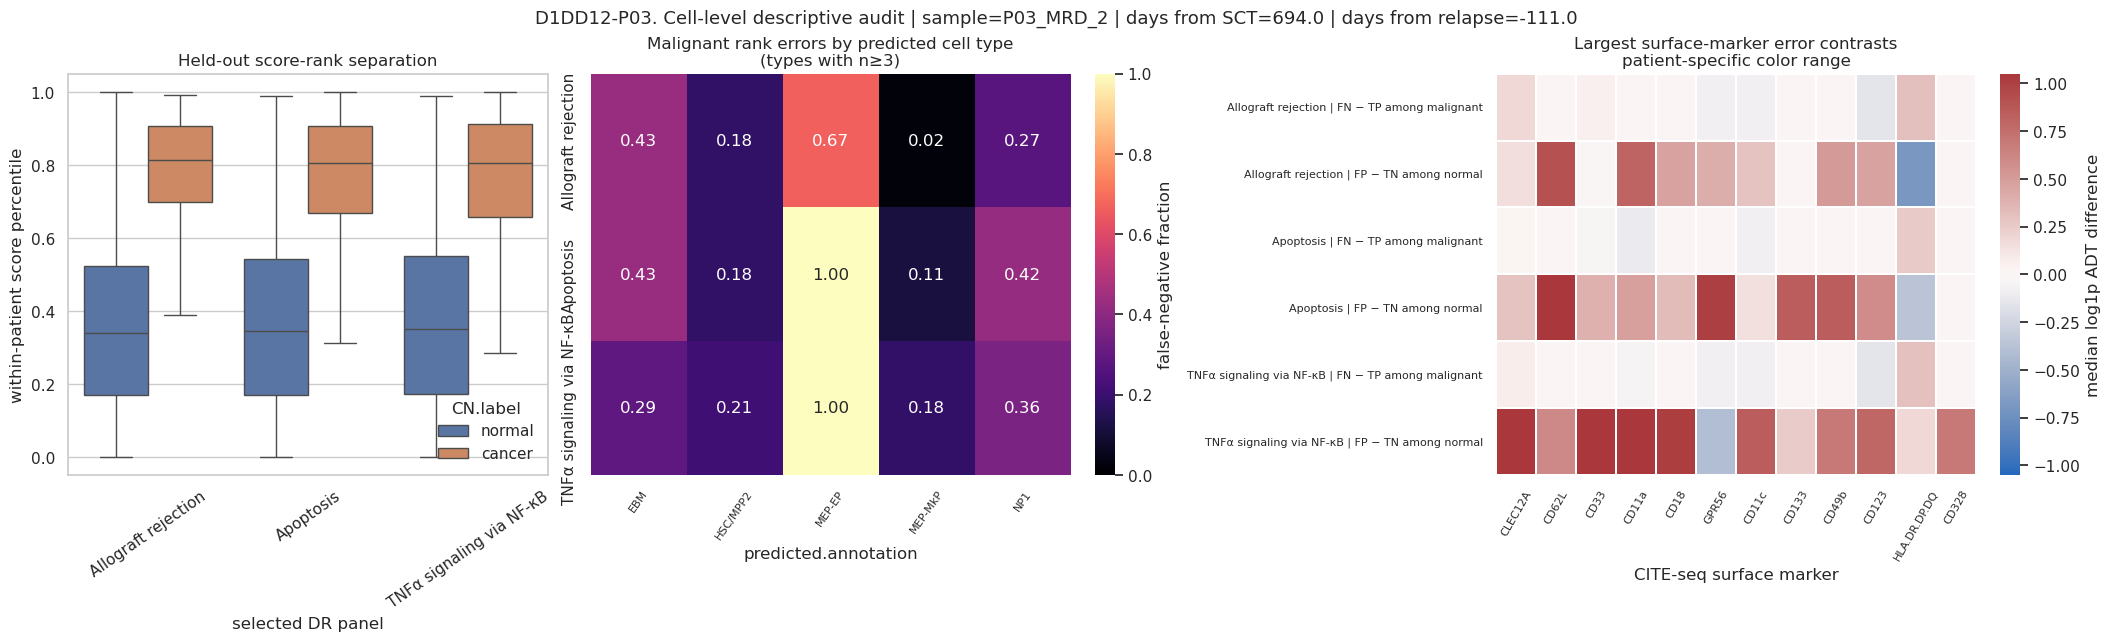

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD12_P04_cell_rank_celltype_adt_audit.png


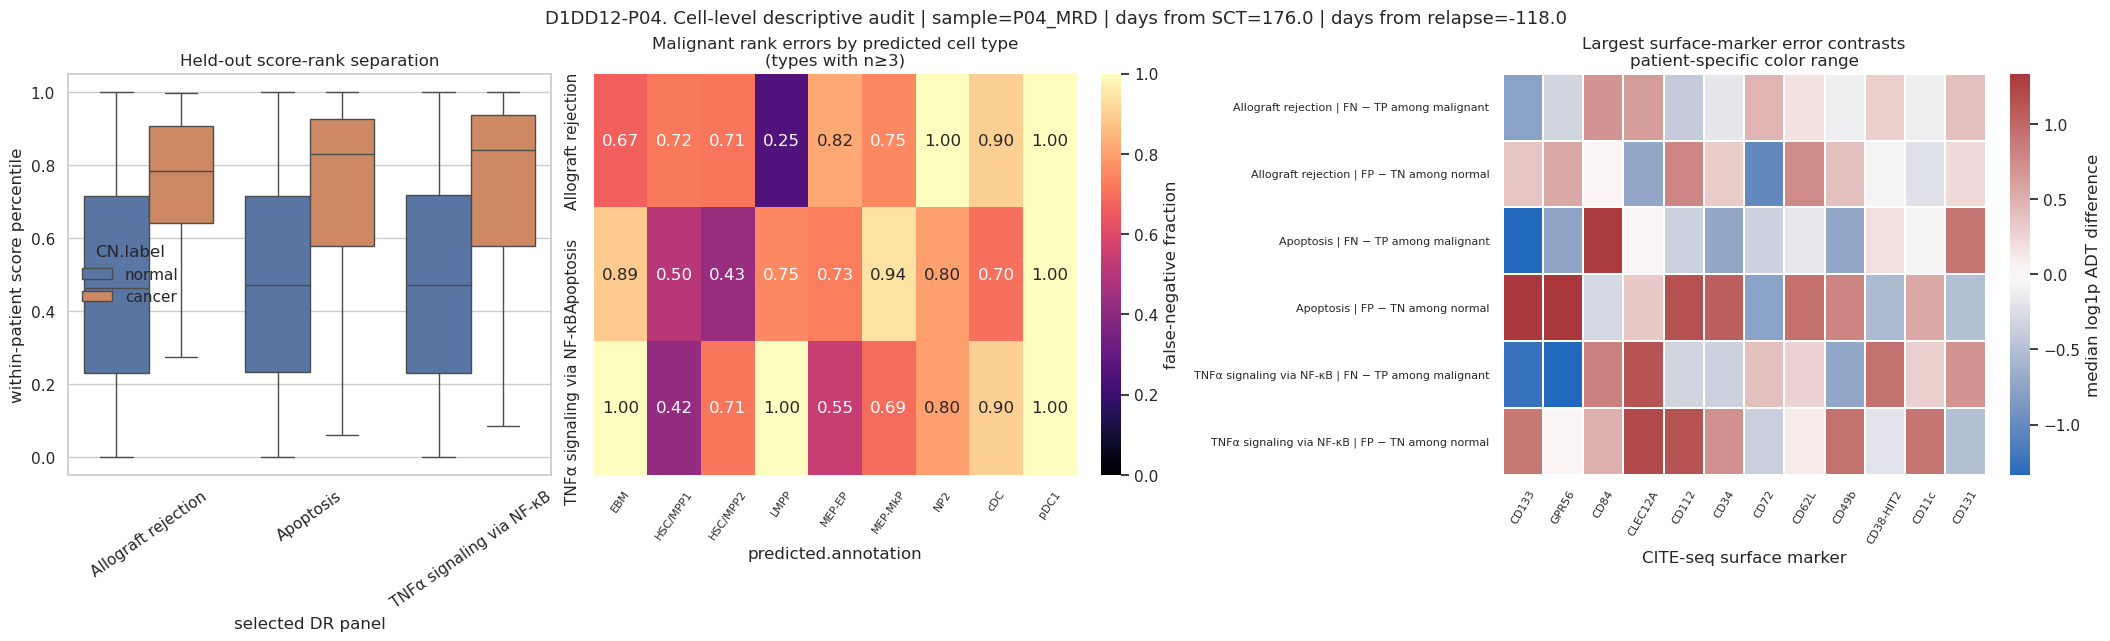

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD12_P06_cell_rank_celltype_adt_audit.png


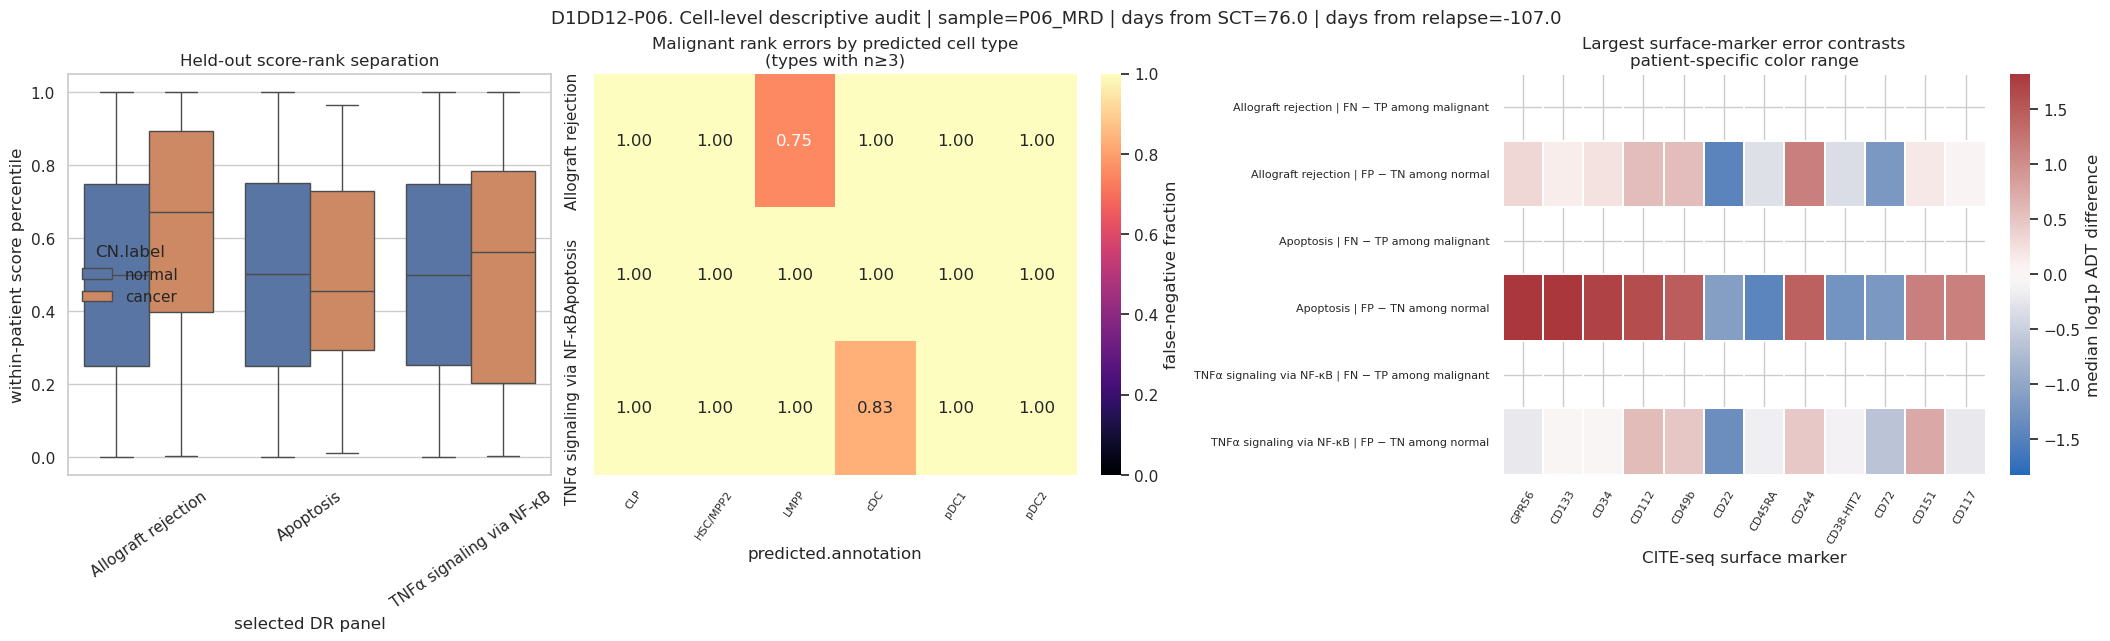

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD12_P07_cell_rank_celltype_adt_audit.png


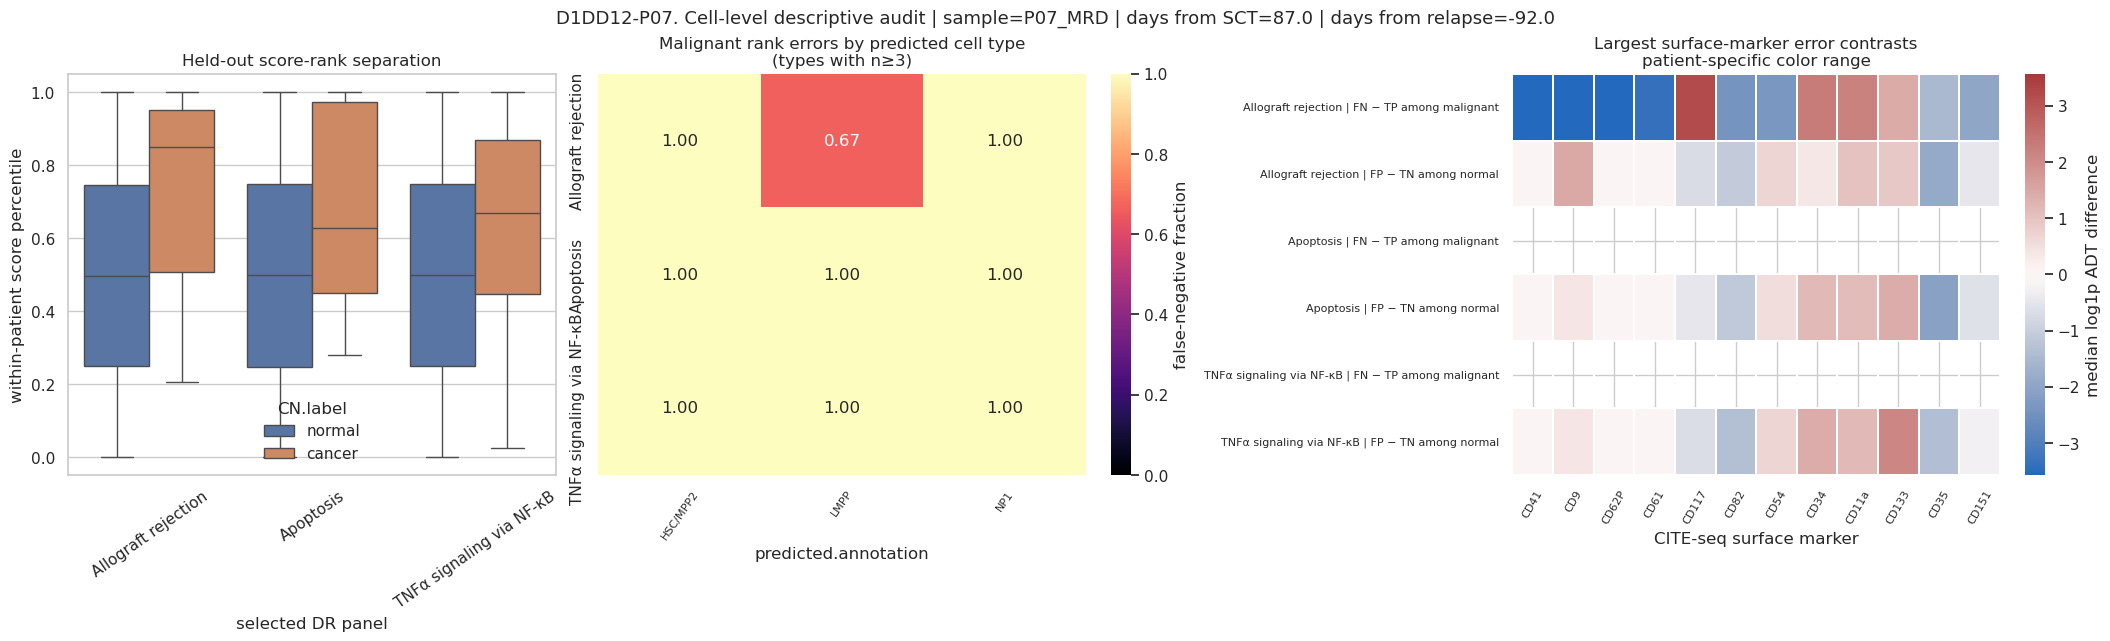

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD12_P09_cell_rank_celltype_adt_audit.png


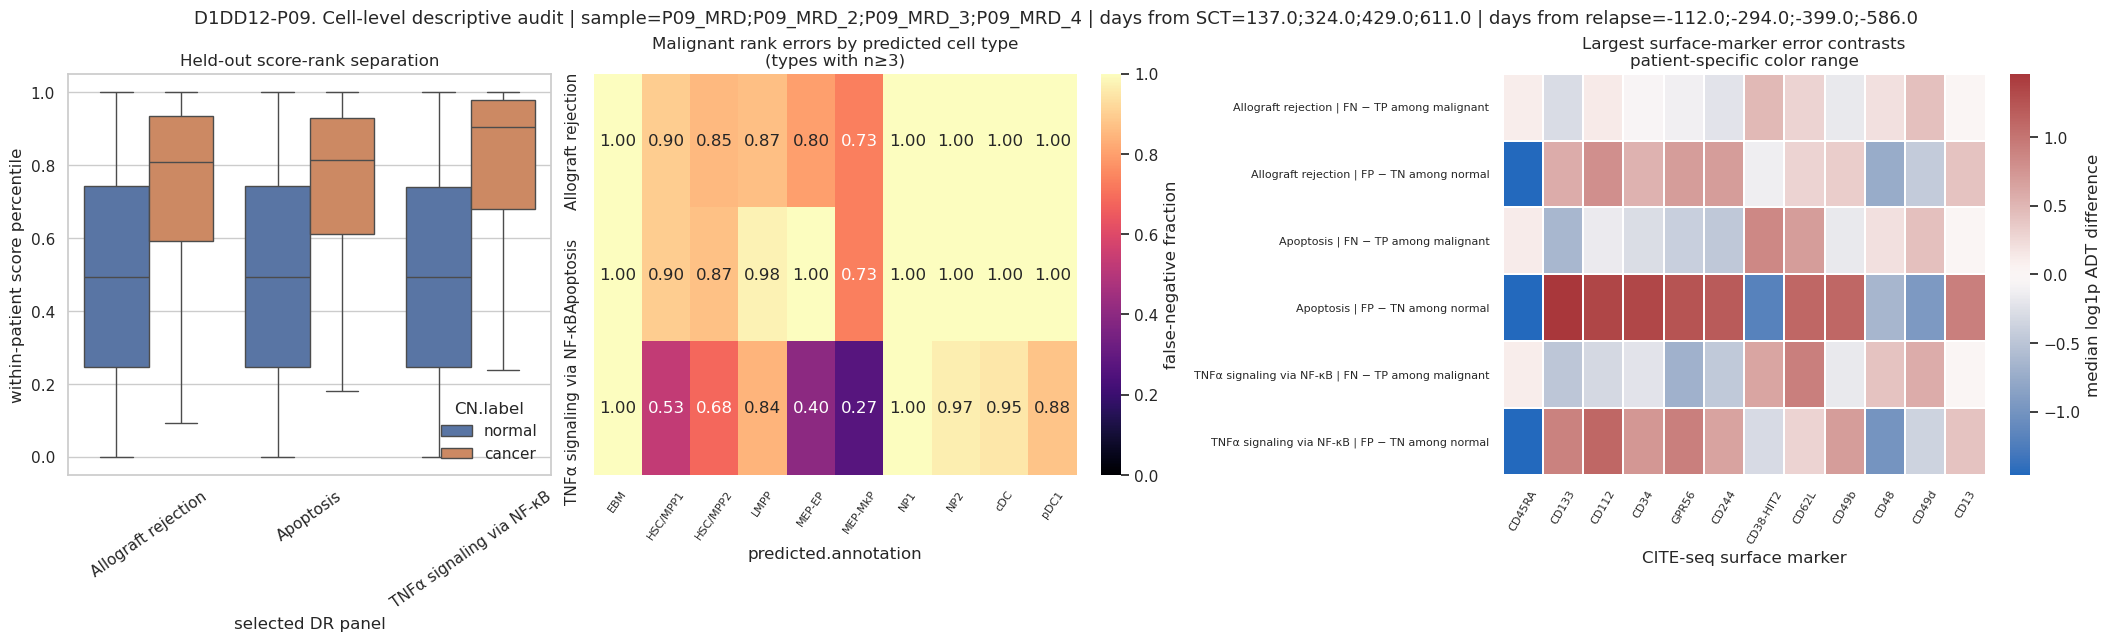

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_surface_protein_rank_error_contrasts.csv
Generated one cell-level audit figure for each supported patient.


In [12]:
# D1DD12 — one figure per supported patient: score ranks, cell types, and surface-protein error contrasts.
adt = cohort.obsm["ADT"]
if not isinstance(adt, pd.DataFrame):
    adt = pd.DataFrame(adt, index=obs.index)
adt.index = adt.index.astype(str)
assert adt.index.equals(obs.index)
adt_columns = [column for column in adt.columns if not str(column).startswith("Isotype-")]
adt_log = np.log1p(adt[adt_columns].astype(np.float32))

adt_contrast_records = []
for patient_id in SUPPORTED_PATIENTS:
    patient_predictions = cell_predictions.loc[cell_predictions["patient"].astype(str).eq(patient_id)].copy()
    contrast_rows = []
    for panel_id, spec in FOCUS.items():
        panel_predictions = patient_predictions.loc[patient_predictions["stage0_panel_id"].eq(panel_id)].set_index("cell_id")
        patient_adt = adt_log.loc[panel_predictions.index]
        for numerator, denominator, contrast_name in [("FN", "TP", "FN − TP among malignant"), ("FP", "TN", "FP − TN among normal")]:
            numerator_ids = panel_predictions.index[panel_predictions["rank_error_group"].eq(numerator)]
            denominator_ids = panel_predictions.index[panel_predictions["rank_error_group"].eq(denominator)]
            if len(numerator_ids) >= 3 and len(denominator_ids) >= 3:
                delta = patient_adt.loc[numerator_ids].median(axis=0) - patient_adt.loc[denominator_ids].median(axis=0)
            else:
                delta = pd.Series(np.nan, index=adt_columns)
            delta.name = f"{spec['label']} | {contrast_name}"
            contrast_rows.append(delta)
            for marker, value in delta.items():
                adt_contrast_records.append(
                    {
                        "heldout_patient": patient_id,
                        "stage0_panel_id": panel_id,
                        "panel": spec["label"],
                        "contrast": contrast_name,
                        "marker": marker,
                        "median_log1p_adt_difference": value,
                        "n_numerator": len(numerator_ids),
                        "n_denominator": len(denominator_ids),
                    }
                )
    contrast_matrix = pd.DataFrame(contrast_rows)
    top_markers = contrast_matrix.abs().max(axis=0).nlargest(12).index

    fig, axes = plt.subplots(1, 3, figsize=(21, 6.3), constrained_layout=True)
    sns.boxplot(
        data=patient_predictions,
        x="panel",
        y="within_patient_score_percentile",
        hue="CN.label",
        order=[spec["label"] for spec in FOCUS.values()],
        hue_order=["normal", "cancer"],
        showfliers=False,
        ax=axes[0],
    )
    axes[0].set_title("Held-out score-rank separation")
    axes[0].set_xlabel("selected DR panel")
    axes[0].set_ylabel("within-patient score percentile")
    axes[0].tick_params(axis="x", rotation=35)
    axes[0].legend(title="CN.label", frameon=False)

    type_matrix = celltype_error.loc[
        celltype_error["patient"].astype(str).eq(patient_id)
        & celltype_error["truth_class"].eq("malignant")
    ].pivot(index="panel", columns="predicted.annotation", values="rank_error_rate").reindex(index=[spec["label"] for spec in FOCUS.values()])
    type_matrix = type_matrix.dropna(axis=1, how="all")
    sns.heatmap(type_matrix, vmin=0, vmax=1, cmap="magma", annot=True, fmt=".2f", cbar_kws={"label": "false-negative fraction"}, ax=axes[1])
    axes[1].set_title("Malignant rank errors by predicted cell type\n(types with n≥3)")
    axes[1].set_xlabel("predicted.annotation")
    axes[1].set_ylabel("")
    axes[1].tick_params(axis="x", rotation=55, labelsize=8)

    adt_vmax = max(float(np.nanquantile(np.abs(contrast_matrix[top_markers].to_numpy()), 0.95)), 0.25) if len(top_markers) else 1.0
    sns.heatmap(
        contrast_matrix[top_markers].rename(columns=lambda value: str(value).replace("ADT-", "")),
        cmap="vlag",
        center=0,
        vmin=-adt_vmax,
        vmax=adt_vmax,
        linewidths=0.25,
        cbar_kws={"label": "median log1p ADT difference"},
        ax=axes[2],
    )
    axes[2].set_title("Largest surface-marker error contrasts\npatient-specific color range")
    axes[2].set_xlabel("CITE-seq surface marker")
    axes[2].set_ylabel("")
    axes[2].tick_params(axis="x", rotation=60, labelsize=8)
    axes[2].tick_params(axis="y", labelsize=8)

    context = patient_context.set_index("patient").loc[patient_id]
    fig.suptitle(
        f"D1DD12-{patient_id}. Cell-level descriptive audit | sample={context['samples']} | "
        f"days from SCT={context['days_from_sct']} | days from relapse={context['days_from_relapse']}",
        fontsize=13,
    )
    save_figure(fig, f"D1DD12_{patient_id}_cell_rank_celltype_adt_audit", dpi=160)
    plt.show()

adt_contrasts = pd.DataFrame(adt_contrast_records)
write_csv(adt_contrasts, "d1dd_surface_protein_rank_error_contrasts.csv")
cohort.file.close()
del adt_log
print("Generated one cell-level audit figure for each supported patient.")

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_rank_matched_confusion_by_sample_collection.csv


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/d1a_deep_dive_20260910/D1DD13_rank_error_by_sample_collection_timing.png


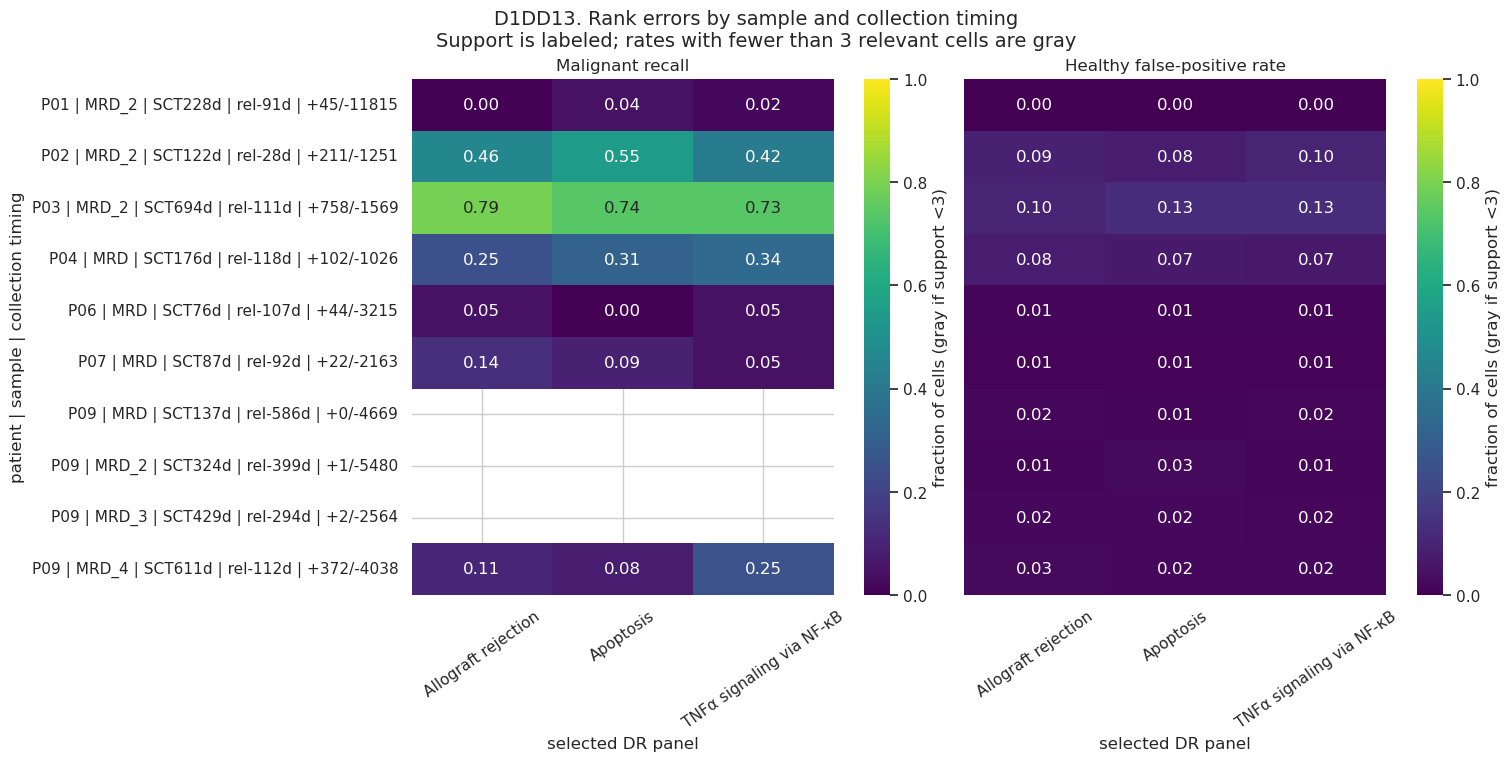

In [13]:
# D1DD13 — sample/collection-time breakdown, especially important for multi-sample P09.
sample_confusion = (
    cell_predictions.groupby(
        ["stage0_panel_id", "panel", "patient", "sample", "Time", "Days from SCT", "Days.from.Relapse", "rank_error_group"],
        observed=True,
    )
    .size()
    .unstack("rank_error_group", fill_value=0)
    .reset_index()
)
for column in ["TP", "FN", "FP", "TN"]:
    if column not in sample_confusion:
        sample_confusion[column] = 0
sample_confusion["n_malignant"] = sample_confusion["TP"] + sample_confusion["FN"]
sample_confusion["n_normal"] = sample_confusion["FP"] + sample_confusion["TN"]
sample_confusion["malignant_recall_at_rank_matched_cutoff"] = sample_confusion["TP"] / sample_confusion["n_malignant"]
sample_confusion["healthy_false_positive_rate_at_rank_matched_cutoff"] = sample_confusion["FP"] / sample_confusion["n_normal"]
sample_confusion["malignant_recall_display"] = sample_confusion["malignant_recall_at_rank_matched_cutoff"].where(sample_confusion["n_malignant"].ge(3))
sample_confusion["healthy_false_positive_rate_display"] = sample_confusion["healthy_false_positive_rate_at_rank_matched_cutoff"].where(sample_confusion["n_normal"].ge(3))
sample_confusion["collection_context"] = sample_confusion.apply(
    lambda row: (
        f"{row['patient']} | {row['Time']} | SCT{row['Days from SCT']:.0f}d | "
        f"rel{row['Days.from.Relapse']:.0f}d | +{int(row['n_malignant'])}/-{int(row['n_normal'])}"
    ),
    axis=1,
)
write_csv(sample_confusion, "d1dd_rank_matched_confusion_by_sample_collection.csv")

collection_order = (
    sample_confusion[["patient", "sample", "Days from SCT", "collection_context"]]
    .drop_duplicates()
    .sort_values(["patient", "Days from SCT"])["collection_context"]
    .tolist()
)
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), sharey=True, constrained_layout=True)
for ax, metric, title in [
    (axes[0], "malignant_recall_display", "Malignant recall"),
    (axes[1], "healthy_false_positive_rate_display", "Healthy false-positive rate"),
]:
    matrix = sample_confusion.pivot(index="collection_context", columns="panel", values=metric).reindex(index=collection_order, columns=[spec["label"] for spec in FOCUS.values()])
    sns.heatmap(matrix, vmin=0, vmax=1, cmap="viridis", annot=True, fmt=".2f", cbar_kws={"label": "fraction of cells (gray if support <3)"}, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("selected DR panel")
    ax.set_ylabel("patient | sample | collection timing" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=35)
fig.suptitle("D1DD13. Rank errors by sample and collection timing\nSupport is labeled; rates with fewer than 3 relevant cells are gray", fontsize=14)
save_figure(fig, "D1DD13_rank_error_by_sample_collection_timing")
plt.show()

## 8. Interpretation and next gates

What this notebook can establish:

- which D1 rows are individual sets, group unions, or controls;
- whether an aggregate K pattern is shared by all seven supported patients;
- which patient/configuration values create the allograft, apoptosis, and TNFα summaries;
- whether the two strongest examples share literal gene membership;
- how much label-free expression structure PCA/FA retain;
- whether a simple one-score mean-z proxy preserves the observed patient ranking;
- which cell types, collection covariates, and surface proteins characterize post-hoc ranking errors.

What it cannot establish:

- that K=40 is a universal optimum or that factors 21–40 are causal;
- that a selected “best” configuration has an unbiased deployment advantage;
- that cell type, donor origin, treatment, or disease biology causes an error pattern;
- that ADT differences are differential-protein discoveries;
- that mean-z is equivalent to UCell/AUCell/ssGSEA;
- that any geneset is significant after matched-gene-set nulls and patient-level multiplicity control.

The next mechanistic layer should inspect the selected factor coefficients and loadings for each focus panel, then ask whether high-scoring and error-enriched cells agree with known allograft, apoptosis, and TNF/NF-κB biology. The next statistical layer is a nested patient-level comparison against expression/detection/size-matched random and HVG panels.

In [14]:
# Plot contracts, concise findings, and artifact validation.
plot_contracts = pd.DataFrame([
    ("D1DD1", "Grouped D1 atlas", "How do panel construction classes differ across all configurations?", "panel × representation", "Median/p20 held-out lift (AUPRC pp)", "Same 777 D1 cells; grouping prevents individual sets, unions, and controls from being conflated."),
    ("D1DD2", "Patient-specific K trend", "Does the central K pattern recur in each supported patient?", "patient × method × K", "Median and 20–80% range across 41 panels", "Still aggregates panels; use D1DD3 for panel-specific behavior."),
    ("D1DD3", "Focus patient/configuration heatmaps", "Which patient values create each focus-panel summary?", "panel × patient × configuration", "Held-out lift (AUPRC pp)", "Exposes patient concentration hidden by D1a/b."),
    ("D1DD4", "Focus K trajectories", "Do median and p20 choose the same K?", "panel × method × K", "Median/p20 lift", "K effects are endpoint- and method-dependent."),
    ("D1DD5", "Selected DR vs direct", "Does the selected DR gain recur patient by patient?", "panel × patient", "Paired lift difference", "Selected configuration is an in-sample winner."),
    ("D1DD6", "Covered-gene overlap", "Are focus panels literal gene-list duplicates?", "gene", "Intersection and Jaccard", "Membership overlap does not measure correlated expression or shared confounding."),
    ("D1DD7", "PCA/FA structure by K", "How much label-free structure is retained as K changes?", "panel × method × K", "PCA total-variance fraction; FA common-variance fraction", "Metrics have different definitions and do not measure label utility."),
    ("D1DD8", "Focus component scree", "Where is K=40 expression structure distributed?", "component/factor", "Per-component and cumulative variance fraction", "FA factor order is display-only loading-energy order."),
    ("D1DD9", "One-score proxy", "Can one overall set score recover the selected multi-factor transfer?", "panel × patient × feature summary", "Held-out lift", "Mean-z is a first-pass proxy, not UCell/AUCell/ssGSEA."),
    ("D1DD10", "Rank-error overview", "At a prevalence-matched rank cutoff, which patients are separated?", "panel × patient × cell", "Recall and false-positive fraction", "Post-hoc cutoff uses held-out prevalence and is not operational."),
    ("D1DD11", "Rank errors by cell type", "Which predicted cell types contain ranking errors?", "panel × patient × predicted cell type", "Within-type rank-error fraction", "Predicted annotation is model-derived; n<3 strata suppressed."),
    ("D1DD12", "Per-patient cell/ADT audit", "What cell-state and surface-marker properties characterize rank errors?", "patient × panel × cell", "Score percentile, FN fraction, median log1p ADT contrast", "Descriptive raw-ADT contrast; no treatment-regimen field or protein-level inference."),
    ("D1DD13", "Sample/collection audit", "Do rank errors differ across repeated samples and collection timing?", "patient × sample × panel × cell", "Recall and false-positive fraction", "Days from SCT/relapse are timing context, not treatment history; rates with relevant-class n<3 are suppressed."),
], columns=["figure_id", "title", "scientific_question", "unit_of_analysis", "metric", "claim_boundary"])
write_csv(plot_contracts, "d1dd_plot_contracts.csv")

one_score_summary = (
    one_score_supported.groupby(["stage0_panel_id", "panel"])["heldout_lift_percentage_points"]
    .agg(mean_z_median_lift_pp="median", mean_z_p20_lift_pp=lambda values: values.quantile(0.20))
    .reset_index()
)
focus_findings = focus_summary.merge(one_score_summary, on=["stage0_panel_id", "panel"], how="left", validate="one_to_one")
write_csv(focus_findings, "d1dd_focus_panel_findings_summary.csv")

winner_k_text = ", ".join(f"K={int(row.K)}: {int(row.n_panel_winners)}" for row in winner_k_counts.itertuples())
winner_method_text = ", ".join(f"{row.method}: {int(row.n_panel_winners)}" for row in winner_method_counts.itertuples())
focus_lines = [
    f"- {row.panel}: selected {row.selected_configuration}, median {row.selected_median_lift_pp:.2f} pp vs direct {row.direct_median_lift_pp:.2f} pp; p20 {row.selected_p20_lift_pp:.2f} pp; mean-z proxy median {row.mean_z_median_lift_pp:.2f} pp."
    for row in focus_findings.itertuples()
]
findings = "\n".join([
    "# D1a descriptive deep-dive findings",
    "",
    "Generated from completed old34 artifacts by `stage2_old34_d1a_descriptive_deep_dives_20260910.ipynb`.",
    "",
    "## Taxonomy and K/method screen",
    "",
    "- D1 contains 34 individual gene sets, 7 biology-group unions, 2 knowledge-union controls, and 4 HVG controls.",
    f"- Best-median DR winner counts among 41 biological panels: {winner_k_text}.",
    f"- Method winner counts: {winner_method_text}. This supports no global dominant method, not method invariance.",
    "",
    "## Focus panels",
    "",
    *focus_lines,
    "",
    "## Gene membership and cell-level audit",
    "",
    f"- Allograft rejection and apoptosis share {len(shared_allograft_apoptosis)} covered genes across a {union_size}-gene union (Jaccard {jaccard_value:.3f}).",
    f"- Selected-DR cell rankings reconstructed with maximum AP error {reconstruction_audit['absolute_error'].max():.2e}.",
    "- Rank-defined TP/FN/FP/TN groups use a post-hoc prevalence-matched cutoff; they are not deployment classifications.",
    "- Patient context includes sample-level collection timing relative to SCT/relapse and 170 ADT markers, but no detailed treatment-regimen field.",
    "",
    "## Claim boundary",
    "",
    "- Descriptive only: selection is not nested, Stage 1 is transductive, and no matched-random/HVG null was run.",
    "- Mean-z is not an AUCell/UCell/ssGSEA implementation; it only operationalizes the one-score concept for the three focus panels.",
    "- Cell-type, sample-time, and ADT patterns nominate mechanistic review; they do not identify causal biology or remove donor/recipient confounding.",
    "",
])
findings_path = TABLE_DIR / "d1a_deep_dive_findings.md"
findings_path.write_text(findings)
GENERATED_TABLES.append(findings_path)
print(findings)

assert len(panel_meta) == 47
assert len(focus_summary) == 3
assert len(reconstruction_audit) == 21
assert reconstruction_audit["absolute_error"].max() < 2e-5
assert len([path for path in GENERATED_FIGURES if path.suffix == ".png"]) == 21
assert all(path.exists() and path.stat().st_size > 0 for path in GENERATED_FIGURES + GENERATED_TABLES)

ledger_rows = []
for path in GENERATED_FIGURES + GENERATED_TABLES:
    stat = path.stat()
    ledger_rows.append({
        "relative_path": str(path.relative_to(EXP_DIR)),
        "artifact_type": "figure" if path.suffix in {".png", ".pdf"} else "table_or_report",
        "size_bytes": stat.st_size,
        "mtime_ns": stat.st_mtime_ns,
    })
ledger = pd.DataFrame(ledger_rows).sort_values(["artifact_type", "relative_path"]).reset_index(drop=True)
ledger_path = TABLE_DIR / "d1dd_artifact_ledger.csv"
ledger.to_csv(ledger_path, index=False)
print(f"Validation passed: {len(GENERATED_FIGURES)//2} PNG/PDF figure pairs, {len(GENERATED_TABLES)} tables/reports.")
print("Artifact ledger:", ledger_path)
display(plot_contracts)

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_plot_contracts.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/d1a_deep_dive_20260910/d1dd_focus_panel_findings_summary.csv
# D1a descriptive deep-dive findings

Generated from completed old34 artifacts by `stage2_old34_d1a_descriptive_deep_dives_20260910.ipynb`.

## Taxonomy and K/method screen

- D1 contains 34 individual gene sets, 7 biology-group unions, 2 knowledge-union controls, and 4 HVG controls.
- Best-median DR winner counts among 41 biological panels: K=10: 4, K=20: 13, K=40: 24.
- Method winner counts: factosig_promax: 12, fa: 11, pca: 9, factosig: 9. This supports no global dominant method, not method invariance.

## Focus panels

- Allograft rejection: selected factosig_promax|K=40, median 12.5

,figure_id,title,scientific_question,unit_of_analysis,metric,claim_boundary
0,D1DD1,Grouped D1 atlas,How do panel construction classes differ across all configurations?,panel × representation,Median/p20 held-out lift (AUPRC pp),"Same 777 D1 cells; grouping prevents individual sets, unions, and controls from being conflated."
1,D1DD2,Patient-specific K trend,Does the central K pattern recur in each supported patient?,patient × method × K,Median and 20–80% range across 41 panels,Still aggregates panels; use D1DD3 for panel-specific behavior.
2,D1DD3,Focus patient/configuration heatmaps,Which patient values create each focus-panel summary?,panel × patient × configuration,Held-out lift (AUPRC pp),Exposes patient concentration hidden by D1a/b.
3,D1DD4,Focus K trajectories,Do median and p20 choose the same K?,panel × method × K,Median/p20 lift,K effects are endpoint- and method-dependent.
4,D1DD5,Selected DR vs direct,Does the selected DR gain recur patient by patient?,panel × patient,Paired lift difference,Selected configuration is an in-sample winner.
5,D1DD6,Covered-gene overlap,Are focus panels literal gene-list duplicates?,gene,Intersection and Jaccard,Membership overlap does not measure correlated expression or shared confounding.
6,D1DD7,PCA/FA structure by K,How much label-free structure is retained as K changes?,panel × method × K,PCA total-variance fraction; FA common-variance fraction,Metrics have different definitions and do not measure label utility.
7,D1DD8,Focus component scree,Where is K=40 expression structure distributed?,component/factor,Per-component and cumulative variance fraction,FA factor order is display-only loading-energy order.
8,D1DD9,One-score proxy,Can one overall set score recover the selected multi-factor transfer?,panel × patient × feature summary,Held-out lift,"Mean-z is a first-pass proxy, not UCell/AUCell/ssGSEA."
9,D1DD10,Rank-error overview,"At a prevalence-matched rank cutoff, which patients are separated?",panel × patient × cell,Recall and false-positive fraction,Post-hoc cutoff uses held-out prevalence and is not operational.
